# Notebook 05 — Del difractograma crudo a números que un químico puede leer

Un difractograma es una **curva**. Una curva no se puede ordenar, ni filtrar, ni
correlacionar, ni meter en un modelo. La pregunta *"enséñame las síntesis con celda
grande y cristalinidad baja"* no es una pregunta que la base de datos pueda contestar
mientras la información viva en forma de curva.

Este cuaderno construye el puente: convierte cada difractograma en **una fila de
números**, y justifica cada uno de esos números con los datos reales del laboratorio.

### Cómo leer este cuaderno

- **No se abre ni un solo fichero del disco.** Todo sale de PostgreSQL con `SELECT`.
  La base de datos es la fuente de verdad; los ficheros crudos bailan entre carpetas
  y no son reproducibles.
- **Todo el cálculo vive en `src/pxrd_descriptors.py`.** El cuaderno lo importa, no lo
  reimplementa. Así el lote de 1.800 medidas y estas figuras usan exactamente el mismo
  código, y no existe la posibilidad de que expliquemos una cosa y ejecutemos otra.
- **Los textos van en español, las figuras en inglés.** Las figuras están pensadas para
  poder salir tal cual en una publicación o en la app.
- **Cada decisión se mide, no se opina.** Cuando aparece un número —un corte angular,
  una λ, un umbral— viene acompañado del experimento que lo eligió.

### Índice

| # | Sección | Qué resuelve |
|---|---|---|
| 1 | Conexión y utilidades | El andamiaje mínimo |
| 2 | Qué hay en la base de datos | Con qué contamos realmente |
| 3 | Por qué hace falta tratar la señal | Dos incompatibilidades: rejilla y escala |
| 4 | **Dónde empieza de verdad la muestra** | El corte a 5°: el haz directo no es señal |
| 5 | Anatomía: tres capas superpuestas | Qué se tira y qué se mide |
| 6 | Calibración de λ | El único parámetro libre, medido contra patrones |
| 7 | Separar halo de picos | Por anchura; y las dos correcciones de ruido |
| 8 | Detección de picos con Poisson | Un umbral que se calibra solo |
| 9 | El caso difícil: picos sobre un halo | Fe + fosfonato de pireno |
| 10 | **El vector completo, descriptor a descriptor** | Las líneas de código, una a una |
| 11 | Validación contra blanco y patrón | ¿Miente el pipeline? |
| 12 | Escribir en `pxrd_descriptors` | El lote |
| 13 | Qué dicen los datos | Estadística del corpus |
| 14 | Buenas prácticas | Lo que conviene no repetir |

# 1. Conexión y utilidades

Tres piezas: `sql()` para consultar, `cargar_curva()` para traer un difractograma ya
puesto sobre la rejilla común, y un estilo de figuras compartido.

`cargar_curva()` hace algo que merece atención: los puntos de la rejilla que caen
**fuera del rango que el equipo midió de verdad se descartan**, nunca se interpolan.
Interpolar ahí sería inventar cuentas en ángulos que el difractómetro no visitó. La
diferencia entre "no hay señal" y "no se miró" tiene que sobrevivir a todo el proceso.

In [1]:
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import psycopg2
from dotenv import load_dotenv

warnings.filterwarnings('ignore')

# El cuaderno se puede lanzar desde la raiz del repo o desde notebooks/
BASE_DIR = os.path.abspath('..') if os.path.isdir('../src') else os.path.abspath('.')
sys.path.insert(0, os.path.join(BASE_DIR, 'src'))
load_dotenv(os.path.join(BASE_DIR, '.env'))

from pxrd_descriptors import (
    GRID_2THETA, WAVELENGTH_CU_KA1, PIPELINE_VERSION,
    LOW_ANGLE_CUTOFF_DEG, LOW_ANGLE_WINDOW_DEG, D_MAX_OBSERVABLE_A,
    DEFAULT_LAMBDA_RIGID, BROAD_WIDTH_DEG, DEFAULT_K_SIGMA,
    BROAD_PEDESTAL_PCT, MIN_SIGNAL_SNR_AREA,
    resample_to_grid, normalize_by_area, arpls_baseline, broad_component,
    decompose_profile, detect_peaks_poisson, poisson_noise_level,
    extract_descriptors, integrate, DESCRIPTOR_COLUMNS,
)


def conectar():
    """Abre una conexion a PostgreSQL con las credenciales del .env."""
    return psycopg2.connect(
        host=os.getenv('POSTGRES_HOST', 'localhost'),
        port=int(os.getenv('POSTGRES_PORT', 5432)),
        dbname=os.getenv('POSTGRES_DB', 'alchemy_db'),
        user=os.getenv('POSTGRES_USER'),
        password=os.getenv('POSTGRES_PASSWORD'),
    )


def sql(consulta, params=None):
    """Ejecuta un SELECT y devuelve un DataFrame."""
    with conectar() as conn:
        return pd.read_sql_query(consulta, conn, params=params)


def _curva_bruta(where_sql, params):
    consulta = f"""
        SELECT data_json->'raw_data'->>'x' AS x,
               data_json->'raw_data'->>'y' AS y
        FROM characterization_measurements
        WHERE {where_sql}
        LIMIT 1;
    """
    with conectar() as conn:
        cur = conn.cursor()
        cur.execute(consulta, params)
        fila = cur.fetchone()
    if fila is None:
        raise ValueError(f'No hay medida para {params}')
    return (np.array(json.loads(fila[0]), dtype=float),
            np.array(json.loads(fila[1]), dtype=float))


def cargar_bruto(sample_code=None, file_name=None, measurement_tag=None):
    """Curva TAL CUAL se midio: sin rejilla y sin recorte. Para ver el crudo."""
    where, params = ["technique IN ('PXRD','VT-XRD')"], []
    for campo, valor in (('sample_code', sample_code), ('file_name', file_name),
                         ('measurement_tag', measurement_tag)):
        if valor is not None:
            where.append(f'{campo} = %s'); params.append(valor)
    return _curva_bruta(' AND '.join(where), params)


def cargar_curva(sample_code=None, file_name=None, measurement_tag=None):
    """
    Curva ya puesta sobre la rejilla comun y recortada al rango medido.

    Los puntos de la rejilla fuera del rango real se DESCARTAN, no se interpolan:
    inventar cuentas en angulos que nunca se visitaron seria fabricar datos.
    """
    x_bruto, y_bruto = cargar_bruto(sample_code, file_name, measurement_tag)
    rejilla, y_rejilla, valido = resample_to_grid(x_bruto, y_bruto)
    return rejilla[valido], y_rejilla[valido]


# --- Estilo de figuras: mismo aspecto en todo el cuaderno --------------------
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10.5, 'axes.titlesize': 12,
    'axes.labelsize': 11, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'legend.frameon': False,
})
C_CRUDO, C_INSTR, C_AMORFO, C_CRIST, C_PICO = '#37474f', '#b06a3c', '#e8a33d', '#1f7a8c', '#c0392b'
XLAB = r'2$\theta$ (degrees, Cu K$\alpha_1$)'

print(f'Version del pipeline : {PIPELINE_VERSION}')
print(f'Rejilla comun        : {GRID_2THETA[0]:.1f}-{GRID_2THETA[-1]:.2f} grados, '
      f'{len(GRID_2THETA)} puntos, paso {GRID_2THETA[1]-GRID_2THETA[0]:.3f}')
print(f'Corte a bajo angulo  : {LOW_ANGLE_CUTOFF_DEG:.1f} grados  ->  d maxima observable {D_MAX_OBSERVABLE_A:.2f} A')

Version del pipeline : v2.0
Rejilla comun        : 5.0-49.98 grados, 2250 puntos, paso 0.020
Corte a bajo angulo  : 5.0 grados  ->  d maxima observable 17.66 A


# 2. Qué hay en la base de datos

Antes de procesar nada conviene saber con qué se cuenta. Dos cosas importan: **cuántas
medidas** y **de qué tipo**. La distinción entre muestra y referencia no es cosmética:
las referencias son las **reglas** con las que se calibra todo lo demás.

In [2]:
inventario = sql("""
    SELECT technique,
           measurement_tag,
           COUNT(*)                            AS n_medidas,
           COUNT(DISTINCT sample_code)         AS n_muestras
    FROM characterization_measurements
    WHERE technique IN ('PXRD', 'VT-XRD', 'SC-XRD')
    GROUP BY technique, measurement_tag
    ORDER BY n_medidas DESC;
""")
display(inventario)
print(f"Total de medidas de difraccion en la BD: {inventario['n_medidas'].sum():,}")

,technique,measurement_tag,n_medidas,n_muestras
0,PXRD,as_synthesized,1870,1808
1,VT-XRD,temperature_series,29,18
2,PXRD,reference_precursor,11,11
3,SC-XRD,simulated_scxrd,11,10
4,PXRD,reference_blank,1,1
5,PXRD,reference_standard,1,1


Total de medidas de difraccion en la BD: 1,923


Las cuatro familias, y para qué sirve cada una:

| `measurement_tag` | Qué es | Para qué se usa aquí |
|---|---|---|
| `as_synthesized` | Las muestras del laboratorio | Es el corpus a describir |
| `reference_blank` | **Portamuestras vacío** | Dice qué mide el equipo cuando no hay nada. Es la regla de "cero" |
| `reference_standard` | Patrón del instrumento | Da la resolución instrumental: la anchura mínima posible de un pico |
| `reference_precursor` | Sales metálicas y ligandos libres | Materiales de partida, sin celda tipo MOF: sirven para distinguir señal de instrumento |
| `simulated_scxrd` | Patrones calculados desde estructuras propias resueltas por monocristal | Comparación para el triaje de novedad |

> **Por qué el blanco y el patrón son imprescindibles y no un lujo.** Un tratamiento de
> señal tiene parámetros libres. Elegirlos "porque en el paper viene así" es una
> opinión. Elegirlos midiendo contra una muestra de la que **se sabe la respuesta**
> —el portamuestras vacío no difracta; el patrón difracta con anchura conocida— es una
> calibración. Todo lo que hace la sección 6 depende de que estas dos medidas existan.

# 3. Por qué hace falta tratar la señal

Dos difractogramas del mismo material pueden ser numéricamente incomparables por
motivos que no tienen nada que ver con la química. Hay dos incompatibilidades y las dos
se ven en los datos reales.

## 3.1 Primera incompatibilidad: cada medida trae su propia rejilla

In [3]:
heterogeneidad = sql("""
    SELECT (data_json->'header_metadata'->>'scan_start_2theta_deg')::float AS inicio,
           (data_json->'header_metadata'->>'scan_end_2theta_deg')::float   AS fin,
           (data_json->'header_metadata'->>'step_size_2theta_deg')::float  AS paso,
           (data_json->'header_metadata'->>'common_counting_time_sec')::float AS t_conteo,
           jsonb_array_length(data_json->'raw_data'->'x')                  AS n_puntos
    FROM characterization_measurements
    WHERE technique = 'PXRD'
      AND data_json->'header_metadata' ? 'scan_start_2theta_deg';
""")

print(f'Medidas con cabecera completa: {len(heterogeneidad):,}\n')
print('Estadistica de la rejilla de medida:')
display(heterogeneidad.describe(percentiles=[.05, .5, .95]).round(3))

Medidas con cabecera completa: 1,883

Estadistica de la rejilla de medida:


,inicio,fin,paso,t_conteo,n_puntos
count,1883.000,1883.000,1883.000,1873.000,1883.000
mean,2.997,38.826,0.013,38.703,2723.841
std,0.320,7.978,0.002,27.980,608.883
min,-2.950,2.953,0.010,3.570,0.000
5%,3.007,34.993,0.013,37.995,2437.000
50%,3.008,34.993,0.013,37.995,2437.000
95%,3.011,54.994,0.013,37.995,3960.000
max,5.007,89.999,0.050,1237.770,6474.000


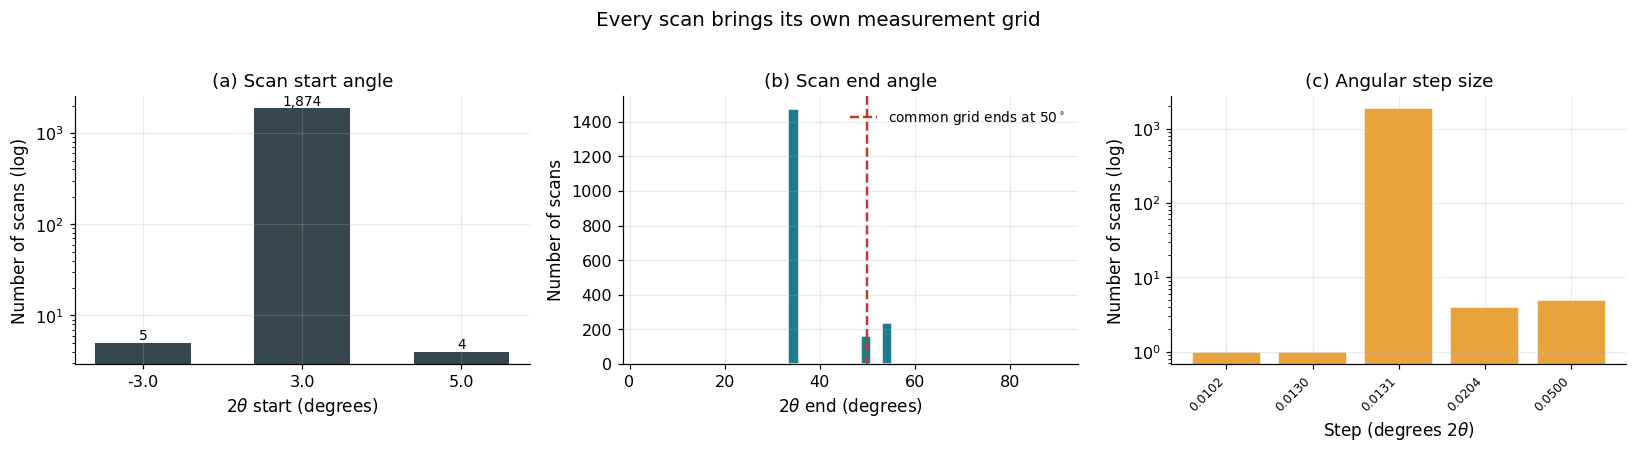

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))

# --- (a) donde EMPIEZA cada barrido -----------------------------------------
ax = axes[0]
conteo_inicio = heterogeneidad['inicio'].round(1).value_counts().sort_index()
ax.bar(conteo_inicio.index.astype(str), conteo_inicio.values, color=C_CRUDO, width=0.6)
for i, v in enumerate(conteo_inicio.values):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax.set_yscale('log')
ax.set_title('(a) Scan start angle')
ax.set_xlabel(r'2$\theta$ start (degrees)'); ax.set_ylabel('Number of scans (log)')

# --- (b) donde TERMINA -------------------------------------------------------
ax = axes[1]
ax.hist(heterogeneidad['fin'].dropna(), bins=40, color=C_CRIST, edgecolor='white')
ax.axvline(GRID_2THETA[-1], color=C_PICO, ls='--', lw=1.6,
           label=f'common grid ends at {GRID_2THETA[-1]:.0f}$^\\circ$')
ax.set_title('(b) Scan end angle')
ax.set_xlabel(r'2$\theta$ end (degrees)'); ax.set_ylabel('Number of scans')
ax.legend(fontsize=9)

# --- (c) paso angular --------------------------------------------------------
ax = axes[2]
pasos = heterogeneidad['paso'].round(4).value_counts().sort_index()
ax.bar(range(len(pasos)), pasos.values, color=C_AMORFO, edgecolor='white')
ax.set_xticks(range(len(pasos)))
ax.set_xticklabels([f'{p:.4f}' for p in pasos.index], rotation=45, ha='right', fontsize=8)
ax.axhline(0, color='none')
ax.set_yscale('log')
ax.set_title('(c) Angular step size')
ax.set_xlabel(r'Step (degrees 2$\theta$)'); ax.set_ylabel('Number of scans (log)')

fig.suptitle('Every scan brings its own measurement grid', fontsize=13, y=1.02)
fig.tight_layout(); plt.show()

**Qué se ve.** Tres histogramas, uno por cada cosa que cambia de una medida a otra:
dónde empieza el barrido, dónde termina y con qué paso avanza. Ninguno es un valor
único. El eje vertical va en escala logarítmica en (a) y (c) porque hay un valor
dominante y varios minoritarios: en escala lineal los minoritarios serían invisibles,
y son justamente los que rompen las comparaciones.

**Por qué esto obliga a una rejilla común.** Restar dos curvas punto a punto exige que
el punto *i* de una y el punto *i* de la otra sean el mismo ángulo. Si una avanza de
0,0131° y otra de 0,0263°, eso no se cumple. La solución es interpolar todas sobre una
**rejilla canónica** —aquí de 0,02°, más fina que el pico más estrecho que el equipo
resuelve, así que no se pierde nada— y **recortar cada curva a su propio rango medido**.

> **La estadística implicada.** Interpolar linealmente entre dos puntos medidos es una
> estimación razonable *dentro* del rango: la señal es continua y el paso es fino.
> Extrapolar *fuera* del rango no lo es, porque no hay ninguna medida que restrinja el
> valor. Por eso `resample_to_grid` devuelve una máscara `valido` en vez de rellenar
> con ceros: un cero es una afirmación ("aquí no difracta"), y no la hemos medido.

## 3.2 Segunda incompatibilidad: la escala de cuentas

Un barrido rápido de cribado y un barrido largo para Rietveld pueden diferir en un
factor 30 en número de cuentas. **Las dos curvas pueden ser del mismo material.**

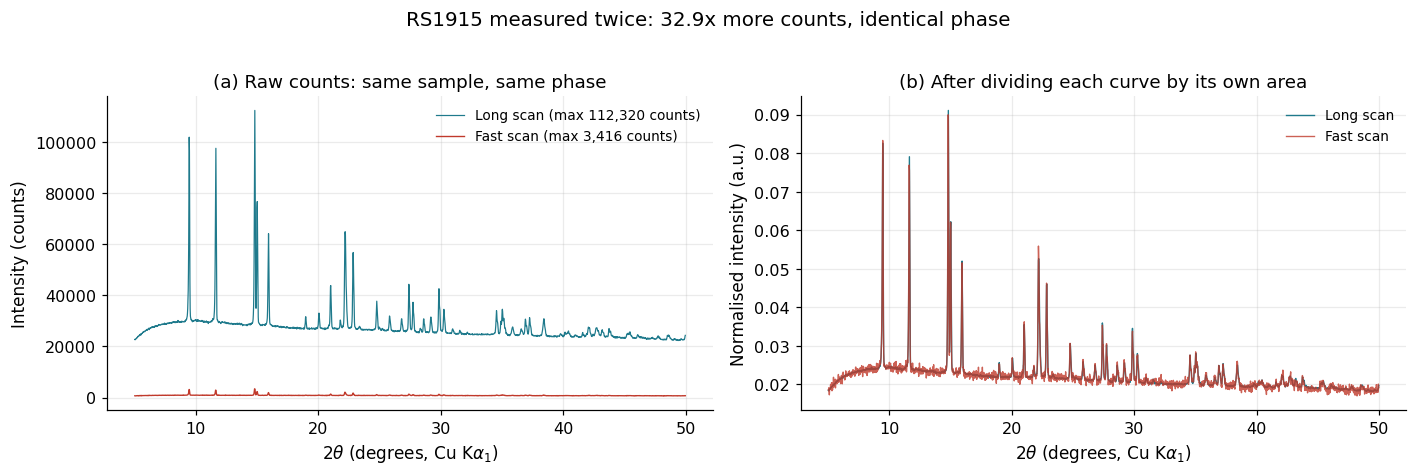

Barrido rapido : max =     3,416 cuentas
Barrido largo  : max =   112,320 cuentas   (32.9 veces mas)


In [5]:
x_rapido, y_rapido = cargar_curva(file_name='24DRX0669-RS1915_CoPy-Test.xrdml')
x_lento,  y_lento  = cargar_curva(file_name='24DRX0669-RS1915_CoPy-Rietveld.xrdml')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

ax = axes[0]
ax.plot(x_lento,  y_lento,  color=C_CRIST, lw=0.8, label=f'Long scan (max {y_lento.max():,.0f} counts)')
ax.plot(x_rapido, y_rapido, color=C_PICO,  lw=0.9, label=f'Fast scan (max {y_rapido.max():,.0f} counts)')
ax.set_title('(a) Raw counts: same sample, same phase')
ax.set_xlabel(XLAB); ax.set_ylabel('Intensity (counts)')
ax.legend(fontsize=9)

ax = axes[1]
ax.plot(x_lento,  normalize_by_area(y_lento,  x_lento),  color=C_CRIST, lw=0.9, label='Long scan')
ax.plot(x_rapido, normalize_by_area(y_rapido, x_rapido), color=C_PICO,  lw=0.9, alpha=0.8, label='Fast scan')
ax.set_title('(b) After dividing each curve by its own area')
ax.set_xlabel(XLAB); ax.set_ylabel('Normalised intensity (a.u.)')
ax.legend(fontsize=9)

fig.suptitle(f'RS1915 measured twice: {y_lento.max()/y_rapido.max():.1f}x more counts, identical phase',
             fontsize=13, y=1.02)
fig.tight_layout(); plt.show()

print(f'Barrido rapido : max = {y_rapido.max():>9,.0f} cuentas')
print(f'Barrido largo  : max = {y_lento.max():>9,.0f} cuentas   ({y_lento.max()/y_rapido.max():.1f} veces mas)')

**Qué se ve.** En (a) la curva roja parece plana. No es que el material sea peor: es
que está dibujada en el eje de la azul, que tiene 33 veces más cuentas. En (b), tras
dividir cada curva por su propia área, las dos se superponen. **La forma es la
información; la altura absoluta es cuánto tiempo estuvo el detector contando.**

> **Y aquí está la razón profunda por la que la normalización va PRIMERO.** El
> algoritmo de línea base que se usa en la sección 6 tiene un parámetro, λ, que
> controla la rigidez de la línea base **en relación al tamaño de los números que está
> ajustando**. Aplicado a cuentas brutas, el mismo λ se comporta como una línea muy
> rígida en un barrido de 200 cuentas y como una muy blanda en uno de 20.000. Las dos
> curvas de arriba se procesarían de forma distinta por un motivo sin ningún contenido
> físico. Normalizando primero, un único λ significa lo mismo para las 1.883 medidas.

# 4. Dónde empieza de verdad la muestra: el corte a bajo ángulo

Esta sección decide un número —dónde empieza la rejilla— y ese número mueve la
cristalinidad de **todo el corpus**. Merece medirse con cuidado.

## 4.1 El problema físico

A ángulos muy bajos, el detector está casi enfrentado a la fuente. Lo que registra ahí
no es difracción de la muestra, es **el haz directo y su dispersión por el aire y por
las rendijas**: fotones que llegan sin haber interaccionado con los planos cristalinos.
Es una cola que decae rápido y que está presente **midas lo que midas**, incluido el
portamuestras vacío.

Si esa cola entra en el procesado, el filtro que busca componentes anchas la
interpretará como un halo amorfo enorme pegado al inicio del rango. El resultado es una
cristalinidad artificialmente baja y una "celda grande" que no existe.

La pregunta no es *si* hay que cortar, sino **dónde**. Tres pruebas independientes.

## 4.2 Prueba 1: la mediana de 200 muestras al azar

Si una subida a bajo ángulo aparece en la **mediana de 200 materiales químicamente
distintos**, no puede ser una reflexión: ningún conjunto de 200 materiales diferentes
comparte una reflexión. Solo el instrumento es común a los 200.

Cada curva se divide antes por su propio nivel en 20–45°, que es zona sin estructura
en casi todas, para que la comparación sea de forma y no de intensidad.

In [6]:
muestras_azar = sql("""
    SELECT data_json->'raw_data'->>'x' AS x, data_json->'raw_data'->>'y' AS y
    FROM characterization_measurements
    WHERE technique = 'PXRD' AND measurement_tag = 'as_synthesized'
      AND (data_json->'raw_data'->'x'->>0)::float BETWEEN 2.9 AND 3.1
    ORDER BY md5(measurement_id::text)
    LIMIT 200;
""")

rejilla_baja = np.arange(3.0, 12.0, 0.05)
apiladas = []
for _, fila in muestras_azar.iterrows():
    xb = np.array(json.loads(fila['x']), float); yb = np.array(json.loads(fila['y']), float)
    nivel = np.median(yb[(xb >= 20) & (xb <= 45)])          # referencia propia de cada curva
    if not np.isfinite(nivel) or nivel <= 0:
        continue
    apiladas.append(np.interp(rejilla_baja, xb, yb / nivel))

apiladas = np.array(apiladas)
mediana = np.median(apiladas, axis=0)
p25, p75 = np.percentile(apiladas, [25, 75], axis=0)

print(f'Curvas apiladas: {len(apiladas)}')
for a in (3.0, 3.5, 4.0, 4.4, 5.0, 6.0, 8.0, 10.0):
    i = int(np.argmin(np.abs(rejilla_baja - a)))
    print(f'  2theta = {a:4.1f} deg  ->  mediana = {mediana[i]:5.2f} x su propio nivel de fondo')

Curvas apiladas: 200
  2theta =  3.0 deg  ->  mediana =  3.56 x su propio nivel de fondo
  2theta =  3.5 deg  ->  mediana =  2.89 x su propio nivel de fondo
  2theta =  4.0 deg  ->  mediana =  1.54 x su propio nivel de fondo
  2theta =  4.4 deg  ->  mediana =  1.28 x su propio nivel de fondo
  2theta =  5.0 deg  ->  mediana =  1.33 x su propio nivel de fondo
  2theta =  6.0 deg  ->  mediana =  1.53 x su propio nivel de fondo
  2theta =  8.0 deg  ->  mediana =  1.25 x su propio nivel de fondo
  2theta = 10.0 deg  ->  mediana =  1.21 x su propio nivel de fondo


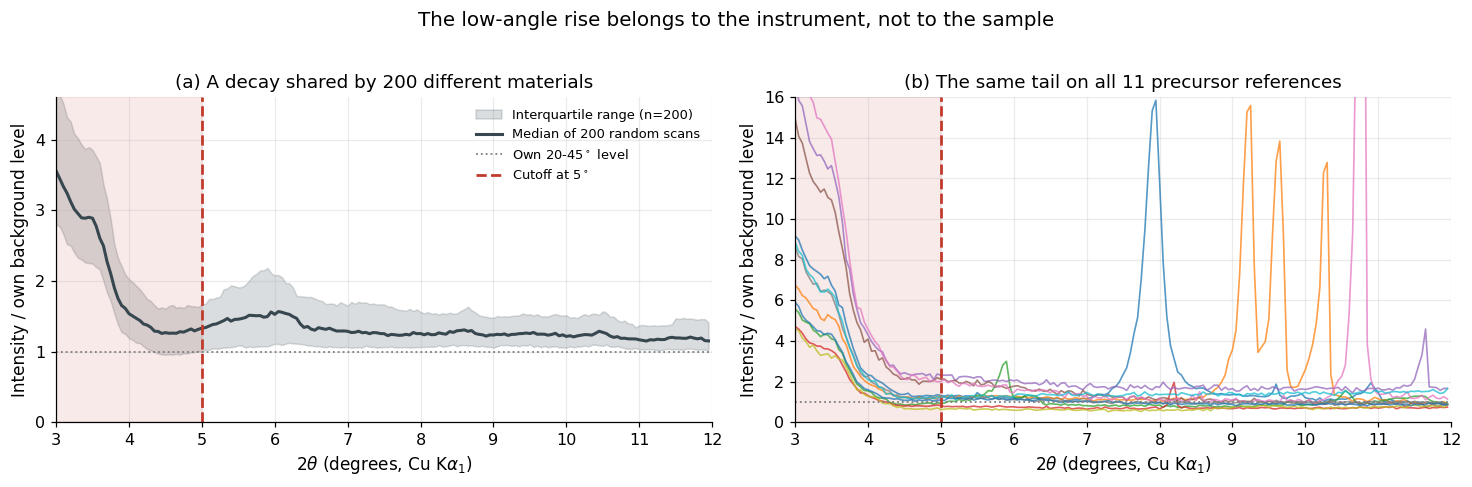

,precursor,3.0-3.5,4.0-4.5,4.5-5.0,6.0-8.0
0,PYPO3H2,7.50,1.77,1.30,1.26
1,PYPO3ET2,5.55,1.48,1.21,1.14
2,Triaz-PO3H2-24.6.21,4.50,1.14,0.90,0.85
3,Ni(NO3)2-6H2O,3.84,0.98,0.80,0.70
4,Ca(NO3)2-4H2O,13.45,3.03,2.32,1.81
5,Zn(NO3)2-6H2O,11.94,2.74,2.07,1.38
6,Bi(NO3)3-5H2O,15.45,3.04,2.09,1.29
7,FeCl3-6H2O,6.83,1.60,1.20,1.03
8,ZrCl4,3.74,0.93,0.65,0.59
9,Mg(NO3)2-6H2O,7.07,1.49,1.20,1.34


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))

ax = axes[0]
ax.fill_between(rejilla_baja, p25, p75, color=C_CRUDO, alpha=0.18, label='Interquartile range (n=200)')
ax.plot(rejilla_baja, mediana, color=C_CRUDO, lw=2.0, label='Median of 200 random scans')
ax.axhline(1.0, color='grey', ls=':', lw=1.2, label='Own 20-45$^\\circ$ level')
ax.axvspan(3.0, LOW_ANGLE_CUTOFF_DEG, color=C_PICO, alpha=0.10)
ax.axvline(LOW_ANGLE_CUTOFF_DEG, color=C_PICO, ls='--', lw=1.8,
           label=f'Cutoff at {LOW_ANGLE_CUTOFF_DEG:.0f}$^\\circ$')
ax.set_xlim(3, 12); ax.set_ylim(0, 4.6)
ax.set_title('(a) A decay shared by 200 different materials')
ax.set_xlabel(XLAB); ax.set_ylabel('Intensity / own background level')
ax.legend(fontsize=8.5, loc='upper right')

# --- prueba 2: los precursores ----------------------------------------------
precursores = sql("""
    SELECT file_name, data_json->'raw_data'->>'x' AS x, data_json->'raw_data'->>'y' AS y
    FROM characterization_measurements
    WHERE measurement_tag = 'reference_precursor'
    ORDER BY file_name;
""")

ax = axes[1]
filas_prec = []
for _, fila in precursores.iterrows():
    xb = np.array(json.loads(fila['x']), float); yb = np.array(json.loads(fila['y']), float)
    if xb.min() > 3.5:
        continue
    nivel = np.median(yb[(xb >= 20) & (xb <= 45)])
    ax.plot(rejilla_baja, np.interp(rejilla_baja, xb, yb / nivel), lw=1.1, alpha=0.75)
    filas_prec.append({
        'precursor': fila['file_name'].split(')-')[-1].replace('.xrdml', ''),
        '3.0-3.5': np.median(yb[(xb >= 3.0) & (xb < 3.5)]) / nivel,
        '4.0-4.5': np.median(yb[(xb >= 4.0) & (xb < 4.5)]) / nivel,
        '4.5-5.0': np.median(yb[(xb >= 4.5) & (xb < 5.0)]) / nivel,
        '6.0-8.0': np.median(yb[(xb >= 6.0) & (xb < 8.0)]) / nivel,
    })
ax.axhline(1.0, color='grey', ls=':', lw=1.2)
ax.axvspan(3.0, LOW_ANGLE_CUTOFF_DEG, color=C_PICO, alpha=0.10)
ax.axvline(LOW_ANGLE_CUTOFF_DEG, color=C_PICO, ls='--', lw=1.8)
ax.set_xlim(3, 12); ax.set_ylim(0, 16)
ax.set_title(f'(b) The same tail on all {len(filas_prec)} precursor references')
ax.set_xlabel(XLAB); ax.set_ylabel('Intensity / own background level')

fig.suptitle('The low-angle rise belongs to the instrument, not to the sample', fontsize=13, y=1.02)
fig.tight_layout(); plt.show()

display(pd.DataFrame(filas_prec).round(2))

**Qué se ve.** En (a), la mediana de 200 muestras vale **3,6 veces** su propio nivel de
fondo a 3,0° y baja monótonamente hasta quedarse en 1,3 hacia **4,4°**. La banda gris es
el rango intercuartílico: no es que unas pocas muestras tengan la cola, la tienen
todas. En (b), los **11 precursores** —sales metálicas y ligandos libres, materiales
que no tienen ninguna celda del tamaño de un MOF— muestran exactamente la misma cola,
entre 3,7 y 15,5 veces a 3,0–3,5°, de vuelta a ~1 hacia 4,5–5,0°.

**Prueba 3, la que cierra el asunto.** El blanco y el patrón del instrumento se
midieron empezando en **5,0066°**. Por debajo de 5° **no existe ninguna referencia**
con la que contrastar el tratamiento. Procesar una región que ninguna regla cubre no es
medir, es suponer.

**Decisión: la rejilla empieza en 5,0°**, el primer ángulo que a la vez (a) deja atrás
la cola con margen y (b) está cubierto por el blanco y el patrón.

## 4.3 Lo que cuesta este corte, dicho abiertamente

La ley de Bragg, $d = \lambda / (2\sin\theta)$, convierte el corte angular en un
**límite de tamaño**: a 5° 2θ con radiación Cu Kα₁ corresponde d = 17,66 Å.

Espaciados mayores existen —en esta familia los núcleos grandes de los ligandos dan
celdas grandes— pero **este difractómetro no los ve**. Eso no es una elección de
procesado, es la ventana del equipo. Lo importante es que el dato no mienta sobre ello:
por eso `pxrd_descriptors` guarda una columna `d_max_saturated` que marca las muestras
cuya primera reflexión cae justo en el corte, donde `d_max_angstrom` es una **cota
inferior** y no una medida.

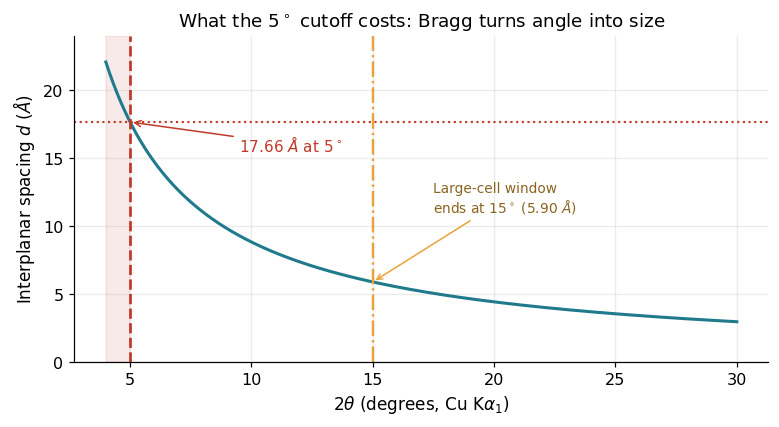

  2theta =   5.0 deg  ->  d =  17.66 A
  2theta =   7.0 deg  ->  d =  12.62 A
  2theta =  10.0 deg  ->  d =   8.84 A
  2theta =  15.0 deg  ->  d =   5.90 A
  2theta =  20.0 deg  ->  d =   4.44 A
  2theta =  30.0 deg  ->  d =   2.98 A


In [8]:
def bragg_d(dos_theta_deg, lam=WAVELENGTH_CU_KA1):
    """Ley de Bragg para primer orden: d = lambda / (2 sin(theta))."""
    return lam / (2.0 * np.sin(np.radians(dos_theta_deg / 2.0)))

fig, ax = plt.subplots(figsize=(7.2, 4.0))
angulos = np.linspace(4.0, 30.0, 500)
ax.plot(angulos, bragg_d(angulos), color=C_CRIST, lw=2.0)
ax.axvline(LOW_ANGLE_CUTOFF_DEG, color=C_PICO, ls='--', lw=1.8)
ax.axhline(D_MAX_OBSERVABLE_A, color=C_PICO, ls=':', lw=1.4)
ax.axvspan(4.0, LOW_ANGLE_CUTOFF_DEG, color=C_PICO, alpha=0.10)
ax.annotate(f'{D_MAX_OBSERVABLE_A:.2f} $\\AA$ at {LOW_ANGLE_CUTOFF_DEG:.0f}$^\\circ$',
            xy=(LOW_ANGLE_CUTOFF_DEG, D_MAX_OBSERVABLE_A), xytext=(9.5, 15.5),
            arrowprops=dict(arrowstyle='->', color=C_PICO), color=C_PICO, fontsize=10)
ax.axvline(LOW_ANGLE_WINDOW_DEG, color=C_AMORFO, ls='-.', lw=1.6)
ax.annotate(f'Large-cell window\nends at {LOW_ANGLE_WINDOW_DEG:.0f}$^\\circ$ ({bragg_d(LOW_ANGLE_WINDOW_DEG):.2f} $\\AA$)',
            xy=(LOW_ANGLE_WINDOW_DEG, bragg_d(LOW_ANGLE_WINDOW_DEG)), xytext=(17.5, 11),
            arrowprops=dict(arrowstyle='->', color=C_AMORFO), color='#8a6520', fontsize=9)
ax.set_xlabel(XLAB); ax.set_ylabel(r'Interplanar spacing $d$ ($\AA$)')
ax.set_title('What the 5$^\\circ$ cutoff costs: Bragg turns angle into size')
ax.set_ylim(0, 24)
fig.tight_layout(); plt.show()

for a in (5.0, 7.0, 10.0, 15.0, 20.0, 30.0):
    print(f'  2theta = {a:5.1f} deg  ->  d = {bragg_d(a):6.2f} A')

> **Nota sobre la ventana de "celda grande" (15°, no 10°).** La línea naranja marca
> dónde se cuentan las reflexiones que indican celda grande. Estos son **P-MOFs**,
> MOFs de fosfonato: densos, con poca porosidad accesible, pero con celdas grandes
> porque los ligandos llevan núcleos voluminosos y la unidad asimétrica es grande y de
> baja simetría. Sus reflexiones más características e intensas caen habitualmente
> **entre 10 y 15°**, así que una ventana de 10° dejaba fuera la mitad de la región
> diagnóstica.
>
> Y una precisión de vocabulario que importa: muchas reflexiones a bajo ángulo indican
> **celda grande**, y celda grande sugiere un armazón **potencialmente poroso**. En
> esta familia, celda grande viene del tamaño del ligando, no necesariamente de que
> haya canales accesibles. Quien decide si hay porosidad de verdad es la adsorción de
> gases, no el difractograma.

# 5. Anatomía de un difractograma: tres capas superpuestas

Un difractograma no es una cosa, son **tres sumadas**, y cada una pide un trato
distinto:

| Capa | Qué es físicamente | Qué se hace con ella |
|---|---|---|
| **Fondo instrumental** | Aire, portamuestras, ruido del detector | **Se tira.** No dice nada del material |
| **Halo amorfo** | Dispersión difusa de la fracción desordenada | **Se mide.** Es literalmente "hay esta cantidad de material sin ordenar" |
| **Picos de Bragg** | Reflexiones de los planos cristalinos | **Se mide.** Es la fase cristalina |

El error clásico es tratar las dos primeras como una sola cosa llamada "fondo" y
quitarlas juntas. Al hacerlo se destruye la cuantificación del rendimiento de
cristalización —el halo *es* el dato— y además desaparecen las reflexiones débiles que
asoman justo por encima del halo, que son precisamente las de las muestras dudosas.

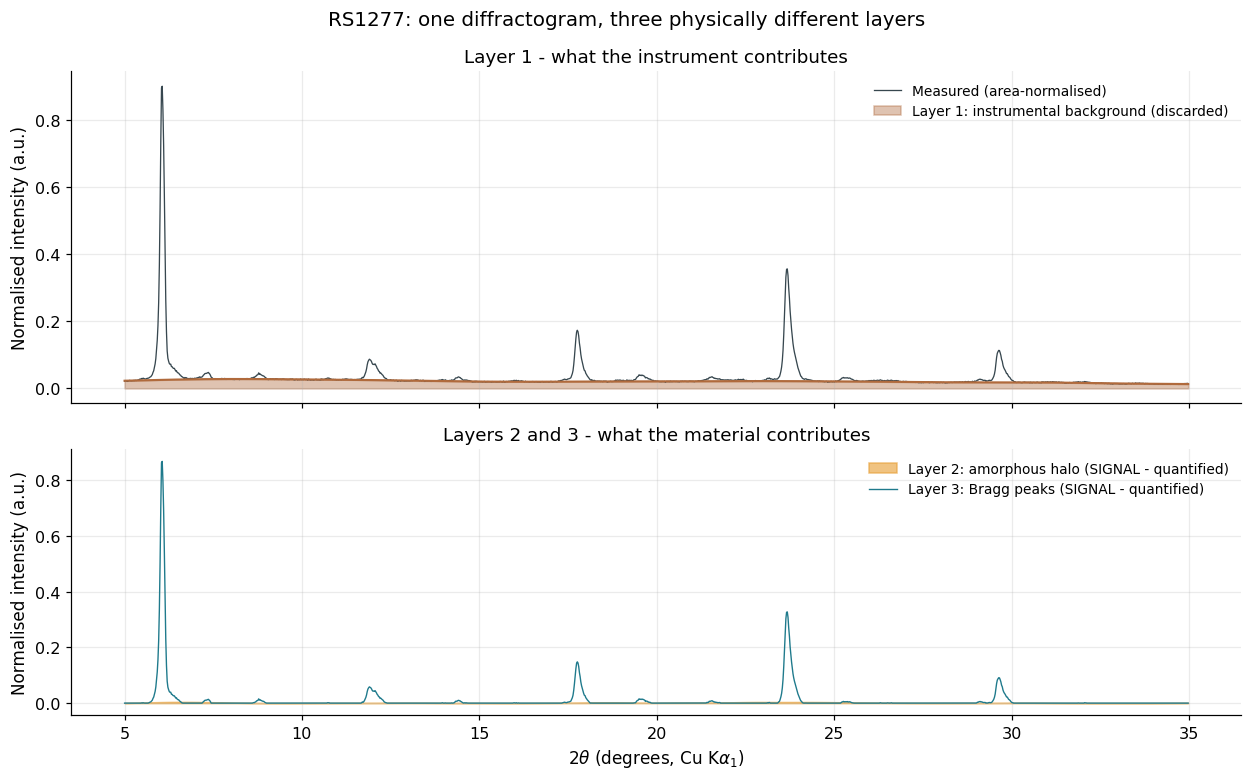

Area cristalina : 0.3134
Area amorfa     : 0.0424
Xc = A_cri / (A_cri + A_amo) = 0.881


In [9]:
x_ana, y_ana = cargar_curva(sample_code='RS1277')
capas = decompose_profile(y_ana, x_ana)

fig, axes = plt.subplots(2, 1, figsize=(11.5, 7.2), sharex=True,
                         gridspec_kw={'height_ratios': [1.25, 1]})

ax = axes[0]
ax.plot(x_ana, capas['normalized'], color=C_CRUDO, lw=0.85, label='Measured (area-normalised)')
ax.fill_between(x_ana, 0, capas['instrumental'], color=C_INSTR, alpha=0.40,
                label='Layer 1: instrumental background (discarded)')
ax.plot(x_ana, capas['instrumental'], color=C_INSTR, lw=1.4)
ax.set_ylabel('Normalised intensity (a.u.)')
ax.set_title('Layer 1 - what the instrument contributes')
ax.legend(fontsize=9)

ax = axes[1]
ax.fill_between(x_ana, 0, capas['amorphous'], color=C_AMORFO, alpha=0.65,
                label='Layer 2: amorphous halo (SIGNAL - quantified)')
ax.plot(x_ana, capas['crystalline'], color=C_CRIST, lw=0.9,
        label='Layer 3: Bragg peaks (SIGNAL - quantified)')
ax.set_xlabel(XLAB); ax.set_ylabel('Normalised intensity (a.u.)')
ax.set_title('Layers 2 and 3 - what the material contributes')
ax.legend(fontsize=9)

fig.suptitle('RS1277: one diffractogram, three physically different layers', fontsize=13, y=0.98)
fig.tight_layout(); plt.show()

a_cri = integrate(capas['crystalline'], x_ana)
a_amo = integrate(capas['amorphous'],  x_ana)
print(f'Area cristalina : {a_cri:.4f}')
print(f'Area amorfa     : {a_amo:.4f}')
print(f'Xc = A_cri / (A_cri + A_amo) = {a_cri/(a_cri+a_amo):.3f}')

**Qué se ve.** Arriba, la curva gris es la medida y la banda marrón lo que aporta el
instrumento: una curva suave, monótona, sin ninguna estructura. Abajo, lo que queda al
restarla, separado en sus dos componentes: la joroba naranja —ancha, con centro y
anchura propios— y las reflexiones azules, estrechas.

La cristalinidad se define sobre **áreas**, no sobre alturas:

$$X_c = \frac{A_{\text{cristalina}}}{A_{\text{cristalina}} + A_{\text{amorfa}}}$$

> **Por qué áreas y no alturas.** Medir la altura de un pico desde cero cuenta dos
> veces el halo que hay debajo, como si fuera cristalino. El sesgo es hacia arriba y es
> **mayor cuanto más halo hay**, es decir, justo en las muestras marginales, que son
> las interesantes. Con áreas, cada fotón se asigna a una capa y a una sola.

# 6. Calibración de λ: el único parámetro libre

## 6.1 Qué hace arPLS, sin fórmulas

**arPLS** (*Asymmetrically Reweighted Penalized Least Squares*, Baek et al., *Analyst*
140 (2015) 250) ajusta una curva suave por debajo de los datos. La imagen mental: metes
un alambre por debajo del difractograma y lo empujas hacia arriba hasta que toca el
suelo de la curva. **λ es lo rígido que es ese alambre.**

- **λ pequeño** → alambre blando: se dobla mucho, se mete por todos los huecos y acaba
  **abrazando la joroba amorfa**. Al restarlo, borras el halo.
- **λ grande** → alambre casi recto: no puede seguir la caída del fondo instrumental y
  **deja fondo sin quitar**.

Lo de *"reponderado asimétricamente"* es el truco que lo hace funcionar. Después de
cada pasada, los puntos que quedan **por encima** del alambre —los picos— reciben un
peso casi nulo, para que el alambre deje de perseguirlos. Formalmente el peso de cada
punto se calcula con una función logística sobre la desviación del residuo negativo:

$$w_i = \frac{1}{1 + \exp\!\left(\dfrac{2\,(d_i - (2\sigma^- - \mu^-))}{\sigma^-}\right)}$$

donde $\mu^-$ y $\sigma^-$ son la media y la desviación típica de los residuos
**negativos** (los puntos que caen por debajo del ajuste). Usar solo los negativos es
la clave: son los que no contienen picos, así que estiman el ruido del fondo sin
contaminarse. Por eso arPLS encuentra el **suelo** del espectro y no su promedio.

## 6.2 Calibrar no es elegir: es medir contra tres reglas

| Patrón | Pregunta | Qué significa fallar |
|---|---|---|
| **Blanco** (portamuestras vacío) | Tras corregir, ¿queda algo? Debería quedar ≈ nada | λ demasiado **alto**: deja fondo |
| **Muestra amorfa** | ¿Sigue estando la joroba? | λ demasiado **bajo**: se la ha comido |
| **Muestra cristalina** | ¿Los picos siguen igual de estrechos? | λ está deformando la FWHM |

Las tres medidas salen de la base de datos. El blanco y la muestra cristalina son
reales; la amorfa es una muestra del corpus con halo evidente.

In [10]:
x_blanco, y_blanco = cargar_curva(measurement_tag='reference_blank')
x_patron, y_patron = cargar_curva(measurement_tag='reference_standard')
x_amorfo, y_amorfo = cargar_curva(sample_code='RS1815')   # amorfa, pero con senal de sobra

LAMBDAS = [1e3, 1e4, 1e5, 1e6, 1e7, 1e8]
filas = []
for lam in LAMBDAS:
    # (1) blanco: cuanto queda tras corregir. Menos es mejor.
    n_b = normalize_by_area(y_blanco, x_blanco)
    residuo_blanco = integrate(np.maximum(n_b - arpls_baseline(n_b, lam=lam), 0), x_blanco)

    # (2) amorfo: sobrevive la joroba?
    capas_a = decompose_profile(y_amorfo, x_amorfo, lam_rigid=lam)
    area_halo = integrate(capas_a['amorphous'], x_amorfo)
    a_c = integrate(capas_a['crystalline'], x_amorfo)
    xc_amorfo = a_c / (a_c + area_halo) if (a_c + area_halo) > 0 else np.nan

    # (3) cristalino: se deforma la anchura de los picos?
    d_p = extract_descriptors(x_patron, y_patron, lam_rigid=lam)

    filas.append({'lambda': lam, 'blanco_residuo': residuo_blanco,
                  'amorfo_area_halo': area_halo, 'amorfo_Xc': xc_amorfo,
                  'patron_FWHM_deg': d_p['fwhm_median_deg'],
                  'patron_n_picos': d_p['n_peaks_k3']})

calibracion = pd.DataFrame(filas)
display(calibracion.round(4))

,lambda,blanco_residuo,amorfo_area_halo,amorfo_Xc,patron_FWHM_deg,patron_n_picos
0,1000.0,0.0399,0.0332,0.7537,0.0780,2
1,10000.0,0.0400,0.0835,0.5328,0.0783,2
2,100000.0,0.0405,0.1089,0.4641,0.0785,2
3,1000000.0,0.0418,0.1357,0.4115,0.0787,2
4,10000000.0,0.0605,0.1567,0.3748,0.0787,2
5,100000000.0,0.0881,0.1628,0.3646,0.0787,2


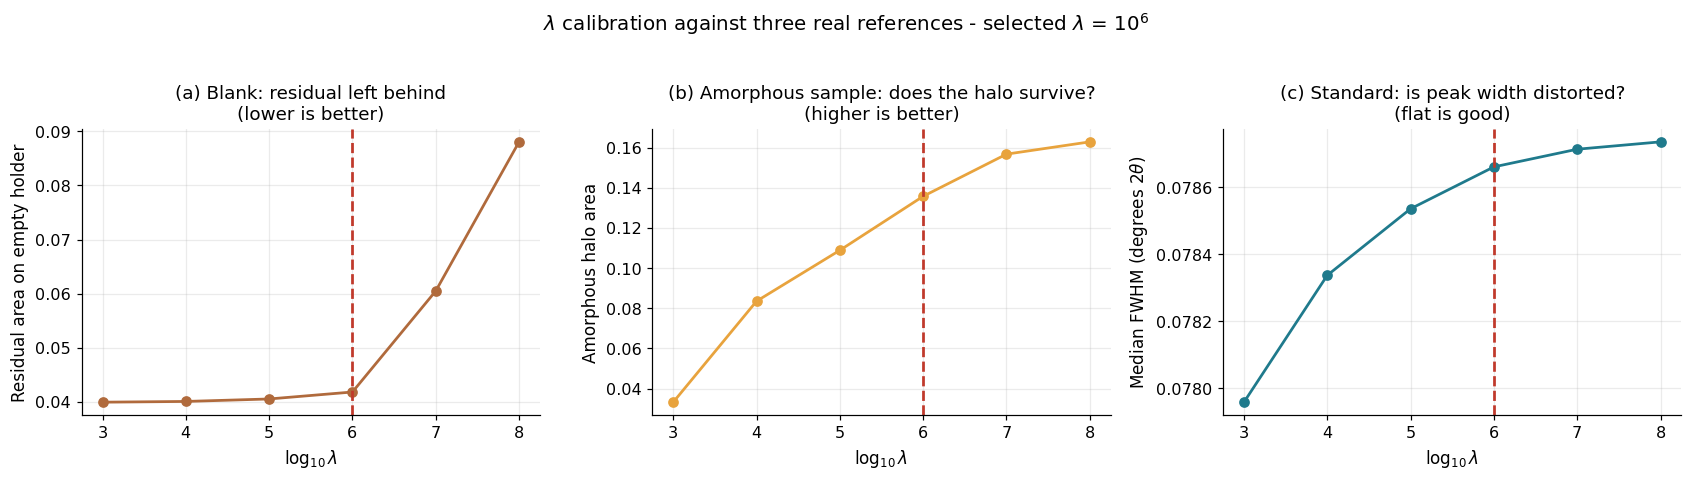

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))
lx = np.log10(calibracion['lambda'])
elegido = np.log10(DEFAULT_LAMBDA_RIGID)

def marca(ax):
    ax.axvline(elegido, color=C_PICO, ls='--', lw=1.8)
    ax.set_xlabel(r'$\log_{10}\lambda$')

ax = axes[0]
ax.plot(lx, calibracion['blanco_residuo'], 'o-', color=C_INSTR, lw=1.8)
marca(ax); ax.set_title('(a) Blank: residual left behind\n(lower is better)')
ax.set_ylabel('Residual area on empty holder')

ax = axes[1]
ax.plot(lx, calibracion['amorfo_area_halo'], 'o-', color=C_AMORFO, lw=1.8)
marca(ax); ax.set_title('(b) Amorphous sample: does the halo survive?\n(higher is better)')
ax.set_ylabel('Amorphous halo area')

ax = axes[2]
ax.plot(lx, calibracion['patron_FWHM_deg'], 'o-', color=C_CRIST, lw=1.8)
marca(ax); ax.set_title('(c) Standard: is peak width distorted?\n(flat is good)')
ax.set_ylabel(r'Median FWHM (degrees 2$\theta$)')

fig.suptitle(f'$\\lambda$ calibration against three real references - selected $\\lambda$ = '
             f'$10^{{{int(np.log10(DEFAULT_LAMBDA_RIGID))}}}$', fontsize=13, y=1.03)
fig.tight_layout(); plt.show()

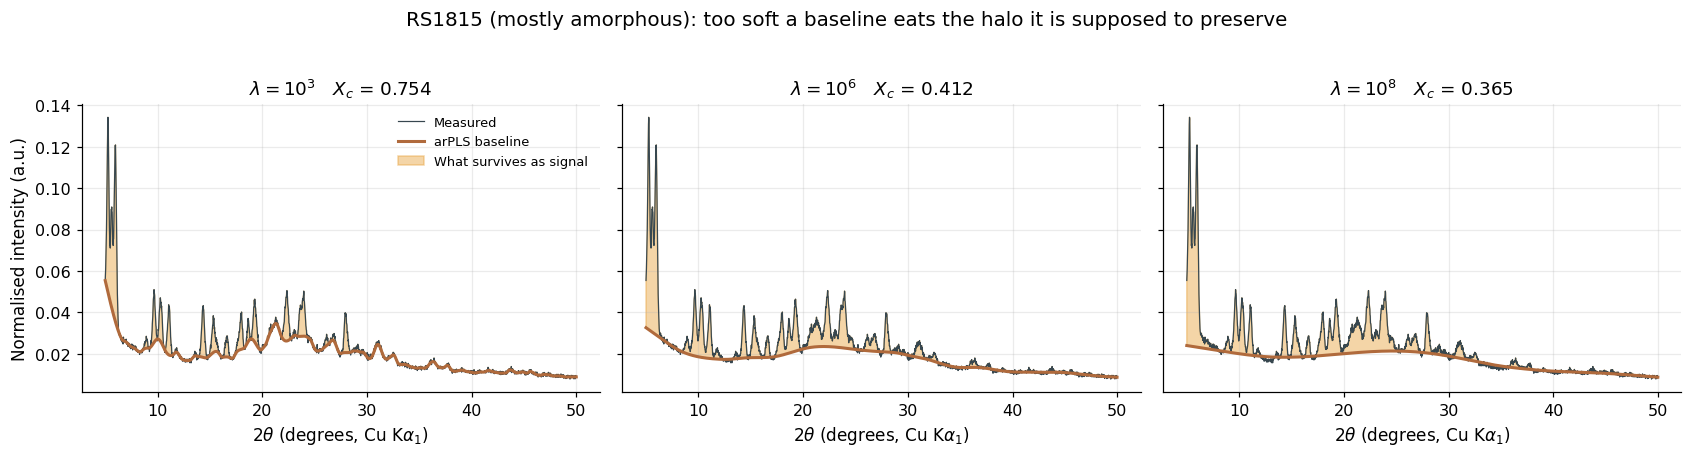

lambda = 1e3 : Xc de una muestra AMORFA = 0.754  <- fabricada
lambda = 1e6 : Xc de la misma muestra   = 0.412
lambda = 1e8 : residuo del blanco       = 0.0881  (2.1x el de 1e6)


In [12]:
# Que le pasa a la joroba amorfa con cada lambda, visto sobre la curva
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0), sharey=True)
n_am = normalize_by_area(y_amorfo, x_amorfo)
for ax, lam in zip(axes, [1e3, DEFAULT_LAMBDA_RIGID, 1e8]):
    base = arpls_baseline(n_am, lam=lam)
    ax.plot(x_amorfo, n_am, color=C_CRUDO, lw=0.8, label='Measured')
    ax.plot(x_amorfo, base, color=C_INSTR, lw=2.0, label='arPLS baseline')
    ax.fill_between(x_amorfo, base, n_am, where=(n_am > base), color=C_AMORFO, alpha=0.45,
                    label='What survives as signal')
    fila = calibracion[calibracion['lambda'] == lam].iloc[0]
    ax.set_title(f'$\\lambda = 10^{{{int(np.log10(lam))}}}$   '
                 f'$X_c$ = {fila["amorfo_Xc"]:.3f}')
    ax.set_xlabel(XLAB)
axes[0].set_ylabel('Normalised intensity (a.u.)')
axes[0].legend(fontsize=8.5)
fig.suptitle('RS1815 (mostly amorphous): too soft a baseline eats the halo it is supposed to preserve',
             fontsize=13, y=1.03)
fig.tight_layout(); plt.show()

fila_baja = calibracion[calibracion['lambda'] == 1e3].iloc[0]
fila_ok   = calibracion[calibracion['lambda'] == DEFAULT_LAMBDA_RIGID].iloc[0]
fila_alta = calibracion[calibracion['lambda'] == 1e8].iloc[0]
print(f"lambda = 1e3 : Xc de una muestra AMORFA = {fila_baja['amorfo_Xc']:.3f}  <- fabricada")
print(f"lambda = 1e6 : Xc de la misma muestra   = {fila_ok['amorfo_Xc']:.3f}")
print(f"lambda = 1e8 : residuo del blanco       = {fila_alta['blanco_residuo']:.4f}  "
      f"({fila_alta['blanco_residuo']/fila_ok['blanco_residuo']:.1f}x el de 1e6)")

**Qué se ve.** Los tres criterios se leen a la vez:

- **(a)** El residuo del blanco crece a partir de λ = 10⁷: la línea base se vuelve tan
  rígida que ya no puede seguir la caída del fondo y **deja fondo sin quitar**.
- **(b)** El área del halo se derrumba por debajo de λ ≈ 10⁴: la línea base se dobla y
  **se come la joroba**. En la figura inferior izquierda se ve directamente: el alambre
  marrón sube y abraza la joroba, y la cristalinidad de una muestra amorfa se dispara.
- **(c)** La anchura de los picos del patrón es plana en casi todo el rango, así que
  este criterio no discrimina: sirve como **control negativo**, confirma que ninguna λ
  razonable está deformando los picos.

**λ = 10⁶** es el codo: el último valor antes de que el residuo del blanco empiece a
dispararse, y ya con el halo prácticamente recuperado del todo.

> **La estadística implicada.** Esto es un barrido de un solo parámetro con tres
> funciones objetivo que tiran en direcciones opuestas. No hay un óptimo matemático
> único: hay una **meseta** donde ninguno de los tres criterios está roto, y se elige el
> centro de la meseta porque es el punto más robusto frente a que una muestra futura se
> comporte algo distinto. Elegir el borde de la meseta funcionaría hoy y fallaría con la
> primera medida atípica.
>
> Y por eso `pxrd_descriptors` guarda `baseline_lambda` en **cada fila**: si algún día
> se recalibra, esa columna es lo único que permitirá saber qué filas son comparables
> entre sí.

# 7. Separar el halo de los picos: por anchura

## 7.1 Por qué no vale una segunda línea base

La idea natural es: *"aplico arPLS otra vez, más blando, y lo que salga es el halo"*.
No funciona, y lo grave es que **no funciona en silencio**.

arPLS es, por definición, un buscador de **suelos**. Si le das una curva cuyo suelo ya
es cero —porque acabas de quitarle el fondo— te devuelve cero. Consecuencia: área
amorfa = 0 y **todas las muestras salen con cristalinidad 1,000**, incluidas las que a
ojo se ve que son amorfas. Números perfectamente creíbles y completamente falsos.

> **Lección general que vale para todo el proyecto:** un algoritmo usado fuera de su
> propósito no suele dar un error; **da un resultado plausible y equivocado**. Cuando
> un cambio de método produce números que "quedan bien", esa es la señal para
> desconfiar, no para celebrar.

## 7.2 Lo que de verdad los distingue es la ANCHURA

- Pico de Bragg: estrecho, **menos de 0,35°** de FWHM.
- Halo amorfo: ancho, **de 5 a 15°**.

Hay dos órdenes de magnitud entre ellos. Así que el filtro tiene que ser selectivo en
**anchura**, no en altura. Se usa una **mediana móvil**: se recorre la curva con una
ventana de 3° y en cada posición se toma el valor mediano de esa ventana.

**Por qué la mediana y no la media.** Una media se desplaza hacia arriba en cuanto la
ventana contiene un pico, porque la media es sensible a valores extremos. La mediana no:
mientras el pico ocupe **menos de la mitad de la ventana**, sigue siendo un valor
extremo dentro del conjunto y la mediana lo ignora. Con ventana de 3° y picos de 0,35°,
un pico ocupa un 12 % de la ventana: la mediana lo salta limpiamente. Es exactamente la
propiedad de robustez de la mediana —su punto de ruptura es del 50 %— puesta a trabajar.

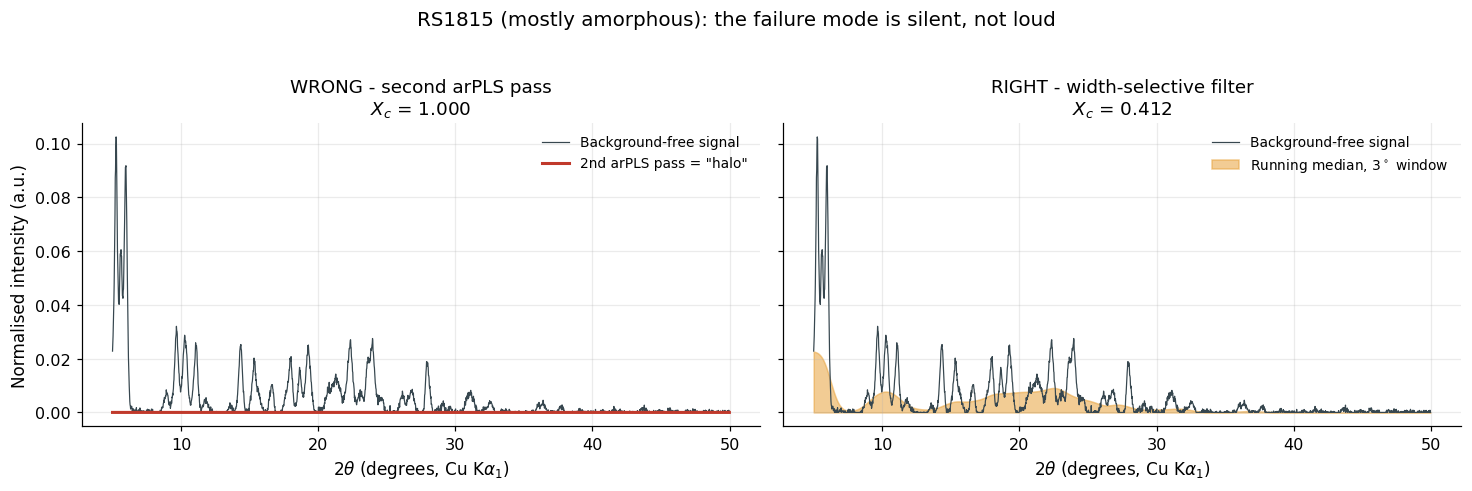

Area del "halo" con 2a pasada arPLS : 0.000000   -> Xc = 1.000
Area del halo con mediana movil     : 0.135735   -> Xc = 0.412


In [13]:
x_sep, y_sep = cargar_curva(sample_code='RS1815')
capas_sep = decompose_profile(y_sep, x_sep)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3), sharey=True)

# --- MAL: una segunda pasada de arPLS ---------------------------------------
neto = capas_sep['net']
halo_malo = arpls_baseline(neto, lam=1e4)
a_h_malo = integrate(np.maximum(halo_malo, 0), x_sep)
a_c_malo = integrate(np.maximum(neto - halo_malo, 0), x_sep)

ax = axes[0]
ax.plot(x_sep, neto, color=C_CRUDO, lw=0.8, label='Background-free signal')
ax.plot(x_sep, np.maximum(halo_malo, 0), color=C_PICO, lw=2.0, label='2nd arPLS pass = "halo"')
ax.set_title(f'WRONG - second arPLS pass\n$X_c$ = {a_c_malo/(a_c_malo+a_h_malo):.3f}')
ax.set_xlabel(XLAB); ax.set_ylabel('Normalised intensity (a.u.)')
ax.legend(fontsize=9)

# --- BIEN: mediana movil selectiva en anchura -------------------------------
ax = axes[1]
ax.plot(x_sep, neto, color=C_CRUDO, lw=0.8, label='Background-free signal')
ax.fill_between(x_sep, 0, capas_sep['amorphous'], color=C_AMORFO, alpha=0.55,
                label=f'Running median, {BROAD_WIDTH_DEG:.0f}$^\\circ$ window')
a_c = integrate(capas_sep['crystalline'], x_sep); a_h = integrate(capas_sep['amorphous'], x_sep)
ax.set_title(f'RIGHT - width-selective filter\n$X_c$ = {a_c/(a_c+a_h):.3f}')
ax.set_xlabel(XLAB)
ax.legend(fontsize=9)

fig.suptitle('RS1815 (mostly amorphous): the failure mode is silent, not loud', fontsize=13, y=1.03)
fig.tight_layout(); plt.show()

print(f'Area del "halo" con 2a pasada arPLS : {a_h_malo:.6f}   -> Xc = {a_c_malo/(a_c_malo+a_h_malo):.3f}')
print(f'Area del halo con mediana movil     : {a_h:.6f}   -> Xc = {a_c/(a_c+a_h):.3f}')

**Qué se ve.** A la izquierda, la línea roja es lo que devuelve una segunda pasada de
arPLS: pegada a cero. El área amorfa resultante es prácticamente nula y la muestra
—que es visiblemente amorfa— sale con cristalinidad cercana a 1. A la derecha, la
mediana móvil recupera la joroba naranja completa y la cristalinidad cae al rango que
corresponde a lo que se ve.

## 7.3 Dos correcciones de ruido, porque las dos componentes se estiman distinto

Separar por anchura deja un problema fino pero importante: **el ruido de conteo también
es estrecho**. Punto a punto, el ruido es independiente de sus vecinos, así que el
filtro de anchura no puede distinguirlo de una reflexión y lo manda entero al lado
cristalino. En una muestra con picos de verdad esto es una fracción despreciable; en
una medida casi vacía, **es todo**.

Y hay un segundo efecto, del lado del halo: arPLS devuelve el **suelo** de los datos, no
su media. Eso significa que incluso en un tramo completamente liso la señal neta
conserva un **pedestal positivo** de aproximadamente uno o dos σ, y la mediana móvil lo
reporta fielmente como "halo". Un halo que no existe.

Las dos correcciones son distintas porque las dos componentes se estiman de forma
distinta:

| Componente | Cómo se estima | Ruido que arrastra | Corrección |
|---|---|---|---|
| **Picos** | Diferencia **punto a punto** | Un σ completo por punto | Restar $k\sigma$ (el mismo criterio que para aceptar un pico) |
| **Halo** | **Mediana de ~150 puntos** | σ/√150 ≈ σ/12, despreciable | Restar el **pedestal**, estimado como el percentil 5 de la propia curva ancha |

El pedestal se estima de la propia muestra —el nivel al que vuelve la componente ancha
donde no hay halo— así que **se autocalibra** y no depende de suponer un modelo de ruido.

La prueba de que hacía falta es el portamuestras vacío.

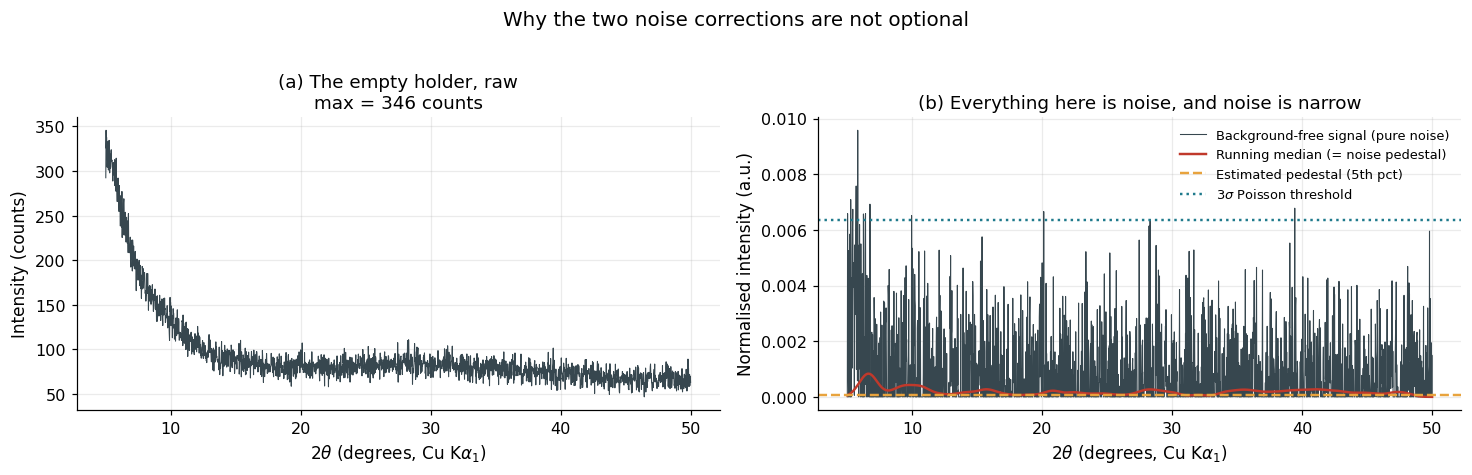

PORTAMUESTRAS VACIO - lo que dice el pipeline sobre "nada":
  crystalline_fraction    = 0.019
  signal_snr_area         = 0.07   (umbral de fiabilidad: 1.0)
  crystallinity_reliable  = False

Sin las dos correcciones, el mismo blanco daba Xc = 0.887: el 89% de su senal
(inexistente) es estrecha, porque es ruido.


In [14]:
d_blanco = extract_descriptors(x_blanco, y_blanco, return_curves=True)
c_bl = d_blanco['_curves']

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))

ax = axes[0]
ax.plot(x_blanco, y_blanco, color=C_CRUDO, lw=0.7)
ax.set_title(f'(a) The empty holder, raw\nmax = {y_blanco.max():,.0f} counts')
ax.set_xlabel(XLAB); ax.set_ylabel('Intensity (counts)')

ax = axes[1]
ax.plot(x_blanco, c_bl['net'], color=C_CRUDO, lw=0.7, label='Background-free signal (pure noise)')
ax.plot(x_blanco, c_bl['broad_raw'], color=C_PICO, lw=1.6, label='Running median (= noise pedestal)')
ax.axhline(c_bl['pedestal'], color=C_AMORFO, lw=1.6, ls='--', label='Estimated pedestal (5th pct)')
ax.axhline(DEFAULT_K_SIGMA * c_bl['noise_level'], color=C_CRIST, lw=1.6, ls=':',
           label=f'{DEFAULT_K_SIGMA:.0f}$\\sigma$ Poisson threshold')
ax.set_title('(b) Everything here is noise, and noise is narrow')
ax.set_xlabel(XLAB); ax.set_ylabel('Normalised intensity (a.u.)')
ax.legend(fontsize=8.5)

fig.suptitle('Why the two noise corrections are not optional', fontsize=13, y=1.02)
fig.tight_layout(); plt.show()

print('PORTAMUESTRAS VACIO - lo que dice el pipeline sobre "nada":')
print(f'  crystalline_fraction    = {d_blanco["crystalline_fraction"]:.3f}')
print(f'  signal_snr_area         = {d_blanco["signal_snr_area"]:.2f}   '
      f'(umbral de fiabilidad: {MIN_SIGNAL_SNR_AREA:.1f})')
print(f'  crystallinity_reliable  = {d_blanco["crystallinity_reliable"]}')
print()
print('Sin las dos correcciones, el mismo blanco daba Xc = 0.887: el 89% de su senal')
print('(inexistente) es estrecha, porque es ruido.')

**Qué se ve.** En (a), el portamuestras vacío: un fondo que decae suavemente, con un
máximo de unos cientos de cuentas. En (b), lo que queda tras quitar ese fondo: **ruido
puro**, sin ninguna estructura. Las tres líneas horizontales son las tres escalas que
importan: dónde está el pedestal que deja arPLS (naranja), dónde está el umbral de 3σ
por encima del cual algo puede considerarse real (azul), y qué recoge la mediana móvil
(rojo).

Con las correcciones, el blanco da **Xc = 0,019 y queda marcado como no fiable**. Sin
ellas daba 0,887. Un portamuestras vacío al 89 % de cristalinidad es el tipo de número
que nadie mira dos veces porque nadie calcula descriptores del blanco — y por eso hay
que calcularlos.

> **`signal_snr_area`, o cuándo un descriptor no es una medida.** Es la señal
> difractada integrada dividida entre el ruido de conteo integrado. Da 0,07 en el
> blanco y 3–5 en una muestra normal: dos órdenes de magnitud de separación. Cuando cae
> por debajo de 1, la división entre halo y picos deja de ser una medida y pasa a ser
> una moneda al aire, así que `crystallinity_reliable` se pone a `FALSE`. **El valor se
> guarda igualmente**, para que la decisión sea auditable, pero la columna booleana
> avisa de que no se debe usar.

# 8. Detección de picos con estadística de Poisson

## 8.1 Por qué no vale un umbral fijo

Detectar rayos X es **contar fotones**. Contar sucesos independientes y raros en un
intervalo fijo sigue la **distribución de Poisson**, cuya propiedad definitoria es que
la varianza es igual a la media:

$$P(k;\mu) = \frac{\mu^{k}e^{-\mu}}{k!}, \qquad \operatorname{Var}(k)=\mu
\;\Longrightarrow\; \sigma = \sqrt{\mu}$$

Es decir: **el ruido es la raíz cuadrada de la señal**, no una fracción de ella.

| Medida | Cuentas | Ruido esperado σ | Ruido relativo |
|---|---|---|---|
| Barrido largo | 10.000 | √10.000 = **100** | 1 % |
| Barrido rápido | 100 | √100 = **10** | 10 % |

Un umbral único —"cuenta como pico todo lo que suba de 50"— **ahogaría los picos reales
del barrido rápido** y **aceptaría ruido del largo**. Por eso el umbral se define como
$k\sqrt{\text{cuentas}}$: se calibra solo con cada medida.

**Qué significa elegir k.** Para μ grande, Poisson se aproxima bien por una normal, así
que k es el número de desviaciones típicas y se traduce en una probabilidad de falso
positivo directamente:

| k | Confianza | Falsos positivos esperados en 2.250 puntos |
|---|---|---|
| 3 | 99,73 % | ≈ 3 |
| 5 | 99,9999 % | ≈ 0,001 |

Por eso se guardan **las dos cuentas**: `n_peaks_k3` es sensible y sirve para no perder
reflexiones débiles; `n_peaks_k5` es conservador y sirve cuando hace falta estar seguro.
Guardar las dos es más honesto que elegir una y ocultar la elección.

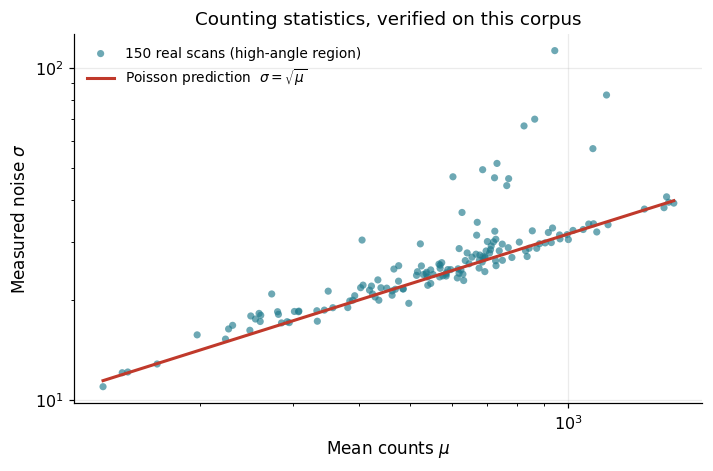

sigma_medido / sqrt(cuentas):  mediana = 1.03   p25 = 0.99   p75 = 1.09
Un valor cercano a 1 confirma que el ruido del equipo es de conteo puro.


In [15]:
# La regla sigma = sqrt(cuentas), comprobada sobre las medidas reales del corpus
ruido_real = sql("""
    SELECT (data_json->'header_metadata'->>'common_counting_time_sec')::float AS t,
           data_json->'raw_data'->>'y' AS y
    FROM characterization_measurements
    WHERE technique = 'PXRD' AND measurement_tag = 'as_synthesized'
    ORDER BY md5(measurement_id::text || 'ruido')
    LIMIT 150;
""")

medias, sigmas = [], []
for _, fila in ruido_real.iterrows():
    yb = np.array(json.loads(fila['y']), float)
    if yb.size < 500:
        continue
    # Tramo alto en angulo: alli casi ninguna muestra tiene estructura, asi que la
    # dispersion que queda es ruido de conteo y no senal.
    tramo = yb[int(0.85 * yb.size):]
    medias.append(np.mean(tramo))
    sigmas.append(np.std(np.diff(tramo)) / np.sqrt(2))   # diferencias: quita la deriva lenta

medias, sigmas = np.array(medias), np.array(sigmas)

fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(medias, sigmas, s=22, color=C_CRIST, alpha=0.65, edgecolor='none',
           label=f'{len(medias)} real scans (high-angle region)')
mm = np.linspace(medias.min(), medias.max(), 100)
ax.plot(mm, np.sqrt(mm), color=C_PICO, lw=2.0, label=r'Poisson prediction  $\sigma=\sqrt{\mu}$')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel(r'Mean counts $\mu$'); ax.set_ylabel(r'Measured noise $\sigma$')
ax.set_title('Counting statistics, verified on this corpus')
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

razon = sigmas / np.sqrt(medias)
print(f'sigma_medido / sqrt(cuentas):  mediana = {np.median(razon):.2f}   '
      f'p25 = {np.percentile(razon,25):.2f}   p75 = {np.percentile(razon,75):.2f}')
print('Un valor cercano a 1 confirma que el ruido del equipo es de conteo puro.')

**Qué se ve.** Cada punto es un barrido real: en horizontal las cuentas medias en la
zona de ángulo alto, en vertical el ruido medido ahí mismo. La línea roja **no es un
ajuste**, es la predicción teórica σ = √μ dibujada encima. Los puntos la siguen a lo
largo de dos órdenes de magnitud.

Esto justifica todo lo que viene después: el umbral de detección no es un número
elegido a mano, se deduce de que el detector cuenta fotones.

*(Detalle de método: el ruido se estima con la desviación típica de las **diferencias**
entre puntos consecutivos, dividida por √2. Restar puntos consecutivos elimina
cualquier deriva lenta del fondo y deja solo la fluctuación punto a punto; el √2 corrige
que la resta de dos variables independientes duplica la varianza.)*

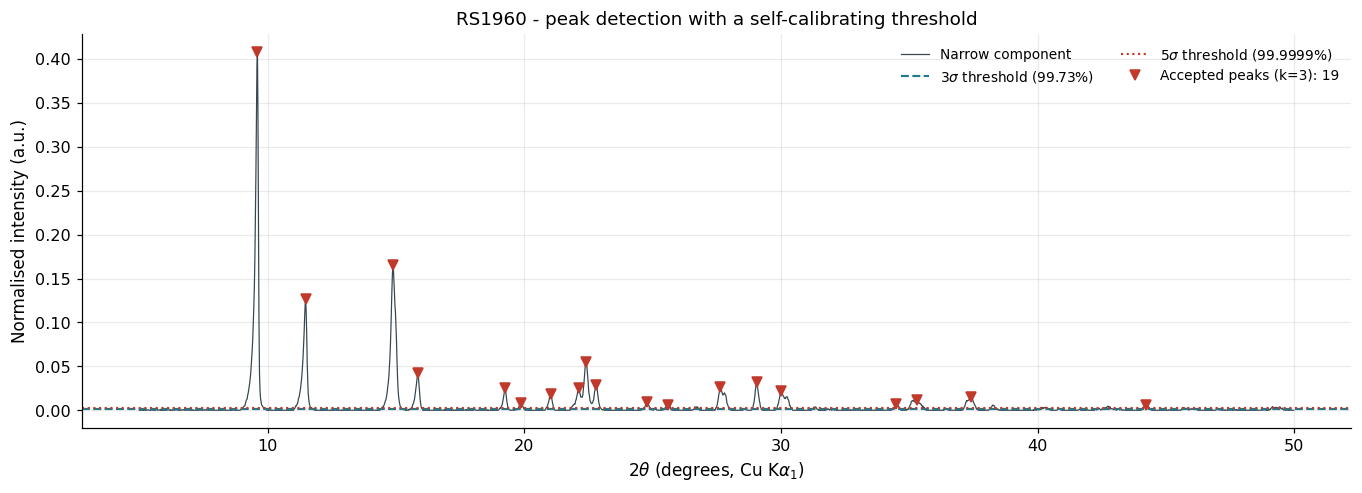

Nivel de ruido sigma (unidades normalizadas): 6.039e-04
Picos aceptados con k=3 : 19
Picos aceptados con k=5 : 19
De ellos, por debajo de 15 grados: 3


In [16]:
x_pk, y_pk = cargar_curva(sample_code='RS1960')
d_pk = extract_descriptors(x_pk, y_pk, return_curves=True)
c_pk = d_pk['_curves']

fig, ax = plt.subplots(figsize=(12.5, 4.6))
ax.plot(x_pk, c_pk['narrow'], color=C_CRUDO, lw=0.8, label='Narrow component')
ax.axhline(3 * c_pk['noise_level'], color=C_CRIST, ls='--', lw=1.4,
           label=r'$3\sigma$ threshold (99.73%)')
ax.axhline(5 * c_pk['noise_level'], color=C_PICO, ls=':', lw=1.4,
           label=r'$5\sigma$ threshold (99.9999%)')
picos = c_pk['peaks']
ax.plot(x_pk[picos], c_pk['narrow'][picos], 'v', color=C_PICO, ms=6,
        label=f'Accepted peaks (k=3): {len(picos)}')
ax.set_xlabel(XLAB); ax.set_ylabel('Normalised intensity (a.u.)')
ax.set_title(f'RS1960 - peak detection with a self-calibrating threshold')
ax.legend(fontsize=9, ncol=2)
fig.tight_layout(); plt.show()

print(f'Nivel de ruido sigma (unidades normalizadas): {c_pk["noise_level"]:.3e}')
print(f'Picos aceptados con k=3 : {d_pk["n_peaks_k3"]}')
print(f'Picos aceptados con k=5 : {d_pk["n_peaks_k5"]}')
print(f'De ellos, por debajo de {LOW_ANGLE_WINDOW_DEG:.0f} grados: {d_pk["n_peaks_below_15deg"]}')

# 9. El caso difícil: picos estrechos sobre un halo amorfo

Los ejemplos limpios no prueban gran cosa. El caso que de verdad pone a prueba la
separación es una muestra **parcialmente cristalizada**: reflexiones nítidas montadas
encima de una joroba ancha. Es el difractograma típico de una síntesis a medio camino,
y es exactamente donde una separación mal hecha inventa cristalinidad.

Dos familias del corpus dan este comportamiento de forma sistemática: **Fe + fosfonato
de pireno (H8ptp)** y **Ti + fosfonato de triazina (H6ttbmp)**. Aquí tres de ellas,
elegidas por tener a la vez el halo más marcado y picos claros.

,sample_code,file_name,metal_center,linker
0,RS598,DRX-22025(4)-RS598-FePy.xrdml,Fe,H8ptp
1,RS1848,RS1848_PXRD.xrdml,Ti,H6ttbmp
2,RS93,RS93_PXRD.xrdml,Fe,Et6ttbmp


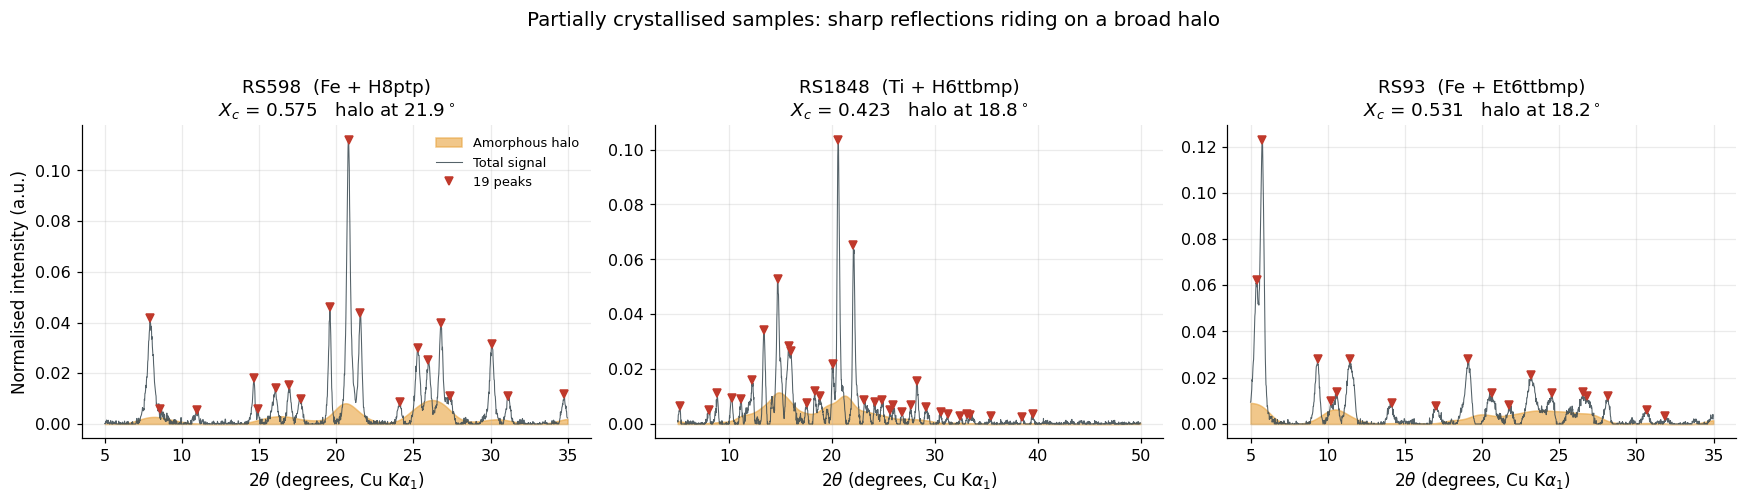

,muestra,metal,Xc,n_picos,halo_centro_deg,halo_FWHM_deg,entropia,SNR_area
0,RS598,Fe,0.575,19,21.856,7.68,8.875,5.262
1,RS1848,Ti,0.423,33,18.797,9.40,9.172,5.284
2,RS93,Fe,0.531,18,18.177,21.72,8.906,5.124


In [17]:
candidatas = sql("""
    SELECT m.sample_code, m.file_name, s.metal_center, s.linker
    FROM characterization_measurements m
    JOIN synthesis_experiments s USING (sample_code)
    WHERE m.technique = 'PXRD'
      AND m.measurement_tag = 'as_synthesized'
      AND m.file_name IN ('RS1848_PXRD.xrdml',
                          'DRX-22025(4)-RS598-FePy.xrdml',
                          'RS93_PXRD.xrdml')
    ORDER BY m.file_name;
""")
display(candidatas)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
resumen = []
for ax, (_, fila) in zip(axes, candidatas.iterrows()):
    xc_, yc_ = cargar_curva(file_name=fila['file_name'])
    d = extract_descriptors(xc_, yc_, sample_code=fila['sample_code'], return_curves=True)
    cur = d['_curves']

    ax.fill_between(xc_, 0, cur['amorphous'], color=C_AMORFO, alpha=0.60,
                    label='Amorphous halo')
    ax.plot(xc_, cur['net'], color=C_CRUDO, lw=0.7, alpha=0.85, label='Total signal')
    ax.plot(xc_[cur['peaks']], cur['net'][cur['peaks']], 'v', color=C_PICO, ms=5,
            label=f'{d["n_peaks_k3"]} peaks')
    ax.set_title(f'{fila["sample_code"]}  ({fila["metal_center"]} + {fila["linker"]})\n'
                 f'$X_c$ = {d["crystalline_fraction"]:.3f}   '
                 f'halo at {d["amorphous_hump_center"]:.1f}$^\\circ$')
    ax.set_xlabel(XLAB)
    resumen.append({'muestra': fila['sample_code'], 'metal': fila['metal_center'],
                    'Xc': d['crystalline_fraction'], 'n_picos': d['n_peaks_k3'],
                    'halo_centro_deg': d['amorphous_hump_center'],
                    'halo_FWHM_deg': d['amorphous_hump_fwhm'],
                    'entropia': d['spectral_entropy'],
                    'SNR_area': d['signal_snr_area']})
axes[0].set_ylabel('Normalised intensity (a.u.)')
axes[0].legend(fontsize=8.5)
fig.suptitle('Partially crystallised samples: sharp reflections riding on a broad halo',
             fontsize=13, y=1.03)
fig.tight_layout(); plt.show()

display(pd.DataFrame(resumen).round(3))

**Qué se ve.** La banda naranja es el halo que el filtro de anchura ha aislado; encima,
en gris, la señal total con los picos marcados. Las tres muestras tienen halo **y**
reflexiones, y la cristalinidad las ordena de forma coherente con lo que se ve: la que
tiene el halo más dominante es la de $X_c$ más bajo.

Fíjate en que el **centro del halo** cae entre 18 y 25°, no pegado al inicio del rango.
Ese es el sitio físicamente esperable para la dispersión difusa de un sólido amorfo con
distancias de contacto de 3–5 Å. Cuando el corte estaba en 3° y la cola del haz directo
entraba en el procesado, este mismo descriptor salía sistemáticamente en **3,8–4,2°**:
el "halo" que medía era el haz.

> **Un descriptor que se puede comprobar contra la física es un descriptor que se puede
> auditar.** El centro del halo tiene un rango esperable; la cristalinidad tiene que
> estar entre 0 y 1; un ángulo no puede pasar de 180°. Verificar rangos físicos cuesta
> una línea de código y caza errores el primer día.

# 10. El vector completo, descriptor a descriptor

Aquí no se da nada por obvio. Para **cada** descriptor: qué significa, **la línea de
código exacta** que lo produce, y qué habría que vigilar al usarlo. Todas las variables
que aparecen (`x`, `neto`, `halo`, `cristalino`, `picos`, `sigma`) son las que devuelve
`extract_descriptors`, así que se puede reproducir cualquiera a mano.

Se calcula una vez el vector de una muestra de referencia y se va desmontando.

In [18]:
MUESTRA_DEMO = 'RS1277'
x, y = cargar_curva(sample_code=MUESTRA_DEMO)
D = extract_descriptors(x, y, sample_code=MUESTRA_DEMO, return_curves=True)
C = D['_curves']

# Los nombres que se usan en el resto de la seccion
normalizado = C['normalized']      # curva / su propia area
instrumental = C['instrumental']   # linea base arPLS (fondo del equipo)
neto         = C['net']            # normalizado - instrumental  = halo + picos
halo         = C['amorphous']      # componente ancha, ya sin pedestal
cristalino   = C['crystalline']    # componente estrecha, ya con el gate de k*sigma
estrecho     = C['narrow']         # componente estrecha SIN gate (para detectar picos)
picos        = C['peaks']          # indices de los maximos aceptados
anchuras     = C['fwhm_deg']       # FWHM de cada pico aceptado, en grados
sigma        = C['noise_level']    # ruido de Poisson en unidades normalizadas

print(f'Muestra {MUESTRA_DEMO}: {len(x)} puntos de rejilla, {len(picos)} picos aceptados')
print(f'sigma = {sigma:.3e} (unidades normalizadas)')

Muestra RS1277: 1500 puntos de rejilla, 8 picos aceptados
sigma = 8.586e-04 (unidades normalizadas)


## 10.1 Trazabilidad — 5 columnas que parecen burocracia y no lo son

Guardan **con qué reglas** se calculó la fila. Cuando dentro de tres meses se recalculen
los descriptores con otra λ, estas columnas son lo único que permitirá saber qué filas
son comparables entre sí. Sin ellas tendrías una tabla con dos generaciones de números
mezclados y ninguna forma de distinguirlos. Es el mismo principio que el `audit_log`.

In [19]:
print(f"pipeline_version = {D['pipeline_version']!r:12s}  version de src/pxrd_descriptors.py")
print(f"baseline_method  = {D['baseline_method']!r:12s}  algoritmo de linea base")
print(f"baseline_lambda  = {D['baseline_lambda']:<12.0f}  rigidez calibrada en la seccion 6")
print(f"broad_width_deg  = {D['broad_width_deg']:<12.1f}  ventana de la mediana movil")
print(f"peak_sigma_k     = {D['peak_sigma_k']:<12.1f}  cuantos sigma exige un pico")

pipeline_version = 'v2.0'        version de src/pxrd_descriptors.py
baseline_method  = 'arpls'       algoritmo de linea base
baseline_lambda  = 1000000       rigidez calibrada en la seccion 6
broad_width_deg  = 3.0           ventana de la mediana movil
peak_sigma_k     = 3.0           cuantos sigma exige un pico


## 10.2 Geometría de los picos — 8 descriptores

### `n_peaks_k3` y `n_peaks_k5` — cuántas reflexiones hay

```python
picos_k3, anchuras = detect_peaks_poisson(x, estrecho, sigma, k_sigma=3.0)
picos_k5, _        = detect_peaks_poisson(x, estrecho, sigma, k_sigma=5.0)
n_peaks_k3 = len(picos_k3)
n_peaks_k5 = len(picos_k5)
```

El descriptor más directo: **cuántas reflexiones distingue el patrón**. Se guardan las
dos versiones porque son dos preguntas distintas —"¿cuántas se intuyen?" y "¿cuántas
son innegables?"— y su **cociente** informa por sí mismo: si k5/k3 es alto, los picos
son robustos; si es bajo, la mayoría estaban justo en el límite del ruido.

Ojo con dos cosas al usarlo como característica de un modelo: depende del **tiempo de
conteo** (un barrido largo resuelve picos que uno rápido no) y satura en patrones muy
poblados, donde picos solapados se cuentan como uno.

### `two_theta_first_peak` — dónde empieza a difractar

```python
two_theta_first_peak = float(x[picos[0]])     # find_peaks los devuelve ordenados
```

La posición de la primera reflexión. En un armazón, cuanto más grande es la celda, más
bajo aparece el primer pico. Es el descriptor de partida para el siguiente.

### `d_max_angstrom` y `d_max_saturated` — el tamaño de celda

```python
theta_rad = np.radians(two_theta_first_peak / 2.0)
d_max_angstrom = WAVELENGTH_CU_KA1 / (2.0 * np.sin(theta_rad))       # ley de Bragg
d_max_saturated = two_theta_first_peak <= LOW_ANGLE_CUTOFF_DEG + 0.10
```

Bragg convertido en tamaño. Es **el descriptor más discriminante entre familias de
MOF**, porque el espaciado mayor es esencialmente el tamaño de la celda.

`d_max_saturated` protege de un error silencioso: si la primera reflexión cae justo en
el corte de 5°, el valor es una **cota inferior**, no una medida. Sin esta bandera un
modelo aprendería el límite del instrumento y lo confundiría con química.

### `fwhm_median_deg` y `fwhm_min_deg` — cómo de estrechos son

```python
fwhm_median_deg = float(np.median(anchuras))   # tipico del patron, robusto a un outlier
fwhm_min_deg    = float(np.min(anchuras))      # el mejor pico: cota superior de calidad
```

La mediana describe el patrón entero; el mínimo describe **el mejor pico**, que es una
cota superior de la calidad cristalina alcanzada. Se guardan los dos porque una muestra
con un pico excelente y muchos anchos no es lo mismo que una uniformemente mediocre.

### `scherrer_size_nm` — tamaño de cristalito

```python
beta_rad = np.radians(float(anchuras[0]))
scherrer_size_nm = (0.9 * (WAVELENGTH_CU_KA1 * 0.1)) / (beta_rad * np.cos(theta_rad))
```

Ecuación de Scherrer: $D = K\lambda/(\beta\cos\theta)$, con K = 0,9, el factor de forma
convencional que se empareja con la **FWHM** (no con la anchura integral: son
convenciones distintas y mezclarlas introduce un sesgo del orden del 10 %). La longitud
de onda se pasa de Å a nm multiplicando por 0,1 para que el resultado salga en nm.

**Advertencia obligada:** Scherrer atribuye *toda* el ensanchamiento al tamaño de
cristalito, ignorando la microdeformación y la contribución del propio instrumento. En
esta familia de materiales debe leerse como un **índice comparativo entre muestras
medidas en el mismo equipo**, no como un tamaño absoluto. Ese es precisamente el papel
del `reference_standard`: da la anchura instrumental por debajo de la cual no se puede
bajar.

In [20]:
# Reproduccion a mano de los ocho, para comprobar que salen los mismos numeros
theta_rad = np.radians(D['two_theta_first_peak'] / 2.0)
d_mano = WAVELENGTH_CU_KA1 / (2.0 * np.sin(theta_rad))
beta_rad = np.radians(float(anchuras[0]))
scherrer_mano = (0.9 * (WAVELENGTH_CU_KA1 * 0.1)) / (beta_rad * np.cos(theta_rad))

print(f"{'descriptor':24s} {'del pipeline':>14s} {'a mano':>14s}")
print('-' * 56)
print(f"{'n_peaks_k3':24s} {D['n_peaks_k3']:>14d} {len(picos):>14d}")
print(f"{'two_theta_first_peak':24s} {D['two_theta_first_peak']:>14.4f} {float(x[picos[0]]):>14.4f}")
print(f"{'d_max_angstrom':24s} {D['d_max_angstrom']:>14.4f} {d_mano:>14.4f}")
print(f"{'fwhm_median_deg':24s} {D['fwhm_median_deg']:>14.4f} {float(np.median(anchuras)):>14.4f}")
print(f"{'fwhm_min_deg':24s} {D['fwhm_min_deg']:>14.4f} {float(np.min(anchuras)):>14.4f}")
print(f"{'scherrer_size_nm':24s} {D['scherrer_size_nm']:>14.4f} {scherrer_mano:>14.4f}")
print()
print(f"n_peaks_k5 / n_peaks_k3 = {D['n_peaks_k5']}/{D['n_peaks_k3']} = "
      f"{D['n_peaks_k5']/max(D['n_peaks_k3'],1):.2f}   (cuanto mas alto, picos mas robustos)")
print(f"d_max_saturated = {D['d_max_saturated']}   (la primera reflexion NO esta en el corte)")

descriptor                 del pipeline         a mano
--------------------------------------------------------
n_peaks_k3                            8              8
two_theta_first_peak             6.0600         6.0600
d_max_angstrom                  14.5728        14.5728
fwhm_median_deg                  0.2006         0.2006
fwhm_min_deg                     0.1419         0.1419
scherrer_size_nm                56.0613        56.0613

n_peaks_k5 / n_peaks_k3 = 8/8 = 1.00   (cuanto mas alto, picos mas robustos)
d_max_saturated = False   (la primera reflexion NO esta en el corte)


## 10.3 Composición de fases — 7 descriptores

### `crystalline_area`, `amorphous_area`, `crystalline_fraction`

```python
crystalline_area     = integrate(cristalino, x)    # regla del trapecio
amorphous_area       = integrate(halo, x)
crystalline_fraction = crystalline_area / (crystalline_area + amorphous_area)
```

El corazón del cuaderno. `integrate` es la regla del trapecio: aproxima el área
sumando trapecios entre puntos consecutivos. Con paso de 0,02° y curvas suaves, el error
es despreciable.

**Las dos áreas se guardan además de la fracción.** La fracción es adimensional y pierde
la escala; las áreas conservan cuánta señal había. Dos muestras con $X_c$ = 0,7 pueden
tener una diez veces más material difractando que la otra.

### `signal_snr_area` y `crystallinity_reliable`

```python
angular_span    = float(x[-1] - x[0])
signal_snr_area = (crystalline_area + amorphous_area) / (sigma * angular_span)
crystallinity_reliable = signal_snr_area >= MIN_SIGNAL_SNR_AREA
```

Señal integrada en unidades de ruido integrado. **Es el descriptor que dice si los
demás son una medida.** Anclas empíricas: blanco 0,07, muestra normal 3–5.

### `amorphous_hump_center` — dónde está el halo

```python
amorphous_hump_center = integrate(x * halo, x) / integrate(halo, x)
```

El centroide del halo: su posición media pesada por intensidad. **Arriba y abajo son
integrales**, así que el paso de la rejilla se cancela y el resultado sale en grados.

> Merece la pena pararse en esto porque es una trampa de cálculo clásica. Si el
> numerador fuese un sumatorio (`np.sum(x * halo)`) y el denominador una integral, las
> dos magnitudes no serían homogéneas: la integral lleva dentro el paso de 0,02° y el
> sumatorio no. El resultado saldría multiplicado por 1/0,02 = **50**, dando ángulos 2θ
> de más de 500° cuando el máximo físico es 180°. **Sospecha siempre de cualquier
> fórmula que mezcle un sumatorio con una integral.**

Físicamente el centro del halo informa de la **distancia de contacto media** en la fase
desordenada: un halo centrado en 20–25° corresponde, vía Bragg, a distancias de 3,5–4,5 Å,
que es lo esperable en un sólido amorfo denso.

### `amorphous_hump_fwhm` — cómo de ancho es

```python
pico_halo = halo.max()
por_encima = np.where(halo >= pico_halo / 2.0)[0]
amorphous_hump_fwhm = float(x[por_encima[-1]] - x[por_encima[0]])
```

Anchura a media altura del halo, medida directamente sobre la curva sin ajustar ninguna
gaussiana. Un halo estrecho apunta a una fase desordenada con orden local a corta
distancia; uno muy ancho, a desorden total.

### `frac_intensity_below_15deg` — celda grande sin depender de detectar picos

```python
ventana = x < LOW_ANGLE_WINDOW_DEG
frac_intensity_below_15deg = integrate(normalizado[ventana], x[ventana])
```

Qué fracción de la intensidad total cae por debajo de 15°. **No necesita detección de
picos**, así que sigue teniendo sentido en una muestra completamente amorfa donde
`n_peaks_below_15deg` es cero. Es el compañero robusto de aquel.

### `peak_to_background_ratio` — contraste

```python
background_level = float(np.median(instrumental))
peak_to_background_ratio = float(np.max(cristalino) / background_level)
```

Cuánto destaca el pico más alto sobre el fondo del equipo. Es una medida de **calidad de
la medida** más que del material: sube con el tiempo de conteo y con la cantidad de
muestra.

In [21]:
# Reproduccion a mano de los siete
a_cri_mano = integrate(cristalino, x)
a_amo_mano = integrate(halo, x)
centro_mano = integrate(x * halo, x) / a_amo_mano
pico_halo = halo.max()
por_encima = np.where(halo >= pico_halo / 2.0)[0]
fwhm_halo_mano = float(x[por_encima[-1]] - x[por_encima[0]])
ventana = x < LOW_ANGLE_WINDOW_DEG
frac_mano = integrate(normalizado[ventana], x[ventana])
snr_area_mano = (a_cri_mano + a_amo_mano) / (sigma * float(x[-1] - x[0]))

print(f"{'descriptor':28s} {'del pipeline':>14s} {'a mano':>14s}")
print('-' * 60)
print(f"{'crystalline_area':28s} {D['crystalline_area']:>14.5f} {a_cri_mano:>14.5f}")
print(f"{'amorphous_area':28s} {D['amorphous_area']:>14.5f} {a_amo_mano:>14.5f}")
print(f"{'crystalline_fraction':28s} {D['crystalline_fraction']:>14.5f} "
      f"{a_cri_mano/(a_cri_mano+a_amo_mano):>14.5f}")
print(f"{'signal_snr_area':28s} {D['signal_snr_area']:>14.5f} {snr_area_mano:>14.5f}")
print(f"{'amorphous_hump_center':28s} {D['amorphous_hump_center']:>14.5f} {centro_mano:>14.5f}")
print(f"{'amorphous_hump_fwhm':28s} {D['amorphous_hump_fwhm']:>14.5f} {fwhm_halo_mano:>14.5f}")
print(f"{'frac_intensity_below_15deg':28s} {D['frac_intensity_below_15deg']:>14.5f} {frac_mano:>14.5f}")
print()
# La trampa del sumatorio contra la integral, con el numero concreto
centro_malo = float(np.sum(x * halo) / integrate(halo, x))
print(f'Centroide bien (integral/integral) : {centro_mano:8.2f} grados')
print(f'Centroide mal  (sumatorio/integral): {centro_malo:8.2f} grados   '
      f'= {centro_malo/centro_mano:.0f}x  (el maximo fisico es 180)')
print(f'El factor es exactamente 1/paso = 1/{x[1]-x[0]:.2f} = {1/(x[1]-x[0]):.0f}')

descriptor                     del pipeline         a mano
------------------------------------------------------------
crystalline_area                    0.31340        0.31340
amorphous_area                      0.04239        0.04239
crystalline_fraction                0.88086        0.88086
signal_snr_area                    13.82225       13.82225
amorphous_hump_center              18.41413       18.41413
amorphous_hump_fwhm                20.06000       20.06000
frac_intensity_below_15deg          0.44501        0.44501

Centroide bien (integral/integral) :    18.41 grados
Centroide mal  (sumatorio/integral):   921.06 grados   = 50x  (el maximo fisico es 180)
El factor es exactamente 1/paso = 1/0.02 = 50


## 10.4 Descriptores globales — 3 que no necesitan detectar ningún pico

Estos tres tienen una virtud que los demás no: **siguen dando un número con sentido en
una muestra completamente amorfa**, donde no hay picos que detectar. Por eso son los
más útiles para ordenar el corpus de peor a mejor.

### `spectral_entropy` — cómo de repartida está la intensidad

```python
p = neto / neto.sum()                       # la curva como distribucion de probabilidad
p = p[p > 0]                                # 0*log(0) = 0, pero log(0) da -inf
spectral_entropy = float(-np.sum(p * np.log2(p)))
```

La **entropía de Shannon**, $H = -\sum p_i \log_2 p_i$, mide cómo de repartida está una
cantidad. Baja = todo concentrado en un sitio. Alta = repartido por todas partes. Su
máximo posible es $\log_2 N$, con $N$ el número de puntos de la curva: unos 11,1 si la
medida cubre la rejilla entera, algo menos si cubre un tramo más corto.

Aplicada al patrón neto:

- Muestra **cristalina** → la intensidad se concentra en **unas pocas reflexiones
  estrechas** → distribución concentrada → entropía **baja**.
- Muestra **amorfa** → la intensidad se reparte por **una joroba ancha** que ocupa
  decenas de grados → distribución extendida → entropía **alta**.

Medida sobre el corpus real, la correlación con la cristalinidad es de **−0,73** (se
comprueba en la sección 13). Es un descriptor barato y sorprendentemente informativo.

> **Una comprobación que conviene tener en cuenta.** Bajo la rejilla anterior, que
> empezaba en 3°, esta misma correlación salía con el **signo contrario** (+0,70), y
> había una explicación física aparentemente convincente para ello. La explicación era
> falsa: lo que concentraba la distribución era la cola del haz directo, un pico
> estrecho a bajo ángulo presente en todas las muestras. Al quitar el instrumento, el
> signo se dio la vuelta y coincidió con la intuición de manual. **Cuando los datos
> contradicen la física conocida, antes de reescribir la física conviene mirar si lo
> que se está midiendo es el equipo.**

> **Un detalle que cambia el resultado por completo:** hay que calcularla sobre la señal
> **neta**, no sobre el patrón completo. Sobre el patrón completo el fondo plano domina
> la distribución, todas las muestras saturan cerca del máximo log₂N y la correlación se
> desploma a +0,04. La entropía mide lo que le des; si le das fondo, mide fondo.

### `snr_global` — relación señal/ruido de verdad

```python
snr_global = float(np.max(neto) / sigma)
```

El pico más alto de la señal **neta** dividido entre el ruido de Poisson. Mide si la
señal destaca sobre la incertidumbre de conteo.

> **Por qué no `max / sqrt(max)`.** Esa fórmula, que parece razonable, se simplifica
> algebraicamente a **exactamente `sqrt(max)`**: no es una relación señal/ruido, es la
> raíz cuadrada de otro descriptor que ya está en la tabla. Para un modelo son dos
> columnas colineales que dicen lo mismo, y el nombre engaña: un patrón de puro ruido
> con muchas cuentas sacaría "SNR excelente". **Conviene simplificar a mano cada
> fórmula antes de darla por buena.**

### `raw_counts_max` — la escala que la normalización borró

```python
raw_counts_max = float(np.max(y_raw))
```

Todo el procesado trabaja con la curva normalizada, así que la escala absoluta
desaparece. Este descriptor la recupera. No es una propiedad del material: es
**cuánta muestra había y cuánto tiempo contó el detector**. Sirve para filtrar medidas
pobres y para explicar por qué una fila tiene `crystallinity_reliable = FALSE`.

In [22]:
p = neto / neto.sum(); p = p[p > 0]
entropia_mano = float(-np.sum(p * np.log2(p)))
snr_mano = float(np.max(neto) / sigma)

print(f"{'descriptor':22s} {'del pipeline':>14s} {'a mano':>14s}")
print('-' * 54)
print(f"{'spectral_entropy':22s} {D['spectral_entropy']:>14.4f} {entropia_mano:>14.4f}")
print(f"{'snr_global':22s} {D['snr_global']:>14.4f} {snr_mano:>14.4f}")
print(f"{'raw_counts_max':22s} {D['raw_counts_max']:>14.0f} {float(np.max(y)):>14.0f}")
print()
print(f'Entropia maxima posible = log2({len(neto)}) = {np.log2(len(neto)):.2f}')
print(f'Esta muestra            = {entropia_mano:.2f}  '
      f'({100*entropia_mano/np.log2(len(neto)):.0f} % del maximo)')
print()
print('La formula enganosa, con numeros:')
for cuentas in (100.0, 10_000.0):
    print(f'  max = {cuentas:>8,.0f}  ->  max/sqrt(max) = {cuentas/np.sqrt(cuentas):>8.1f}'
          f'   = sqrt(max) = {np.sqrt(cuentas):>8.1f}')

descriptor               del pipeline         a mano
------------------------------------------------------
spectral_entropy               7.3672         7.3670
snr_global                  1019.0901      1019.0901
raw_counts_max                  28447          28447

Entropia maxima posible = log2(1500) = 10.55
Esta muestra            = 7.37  (70 % del maximo)

La formula enganosa, con numeros:
  max =      100  ->  max/sqrt(max) =     10.0   = sqrt(max) =     10.0
  max =   10,000  ->  max/sqrt(max) =    100.0   = sqrt(max) =    100.0


In [23]:
# El vector completo de esta muestra, en formato legible
vector = pd.DataFrame(
    [(k, D[k]) for k in DESCRIPTOR_COLUMNS],
    columns=['descriptor', f'{MUESTRA_DEMO}']
)
pd.set_option('display.max_rows', 60)
display(vector)
print(f'{len(DESCRIPTOR_COLUMNS)} descriptores por medida.')

,descriptor,RS1277
0,pipeline_version,v2.0
1,baseline_method,arpls
2,baseline_lambda,1000000.0
3,broad_width_deg,3.0
4,peak_sigma_k,3.0
5,n_peaks_k3,8
6,n_peaks_k5,8
7,n_peaks_below_15deg,4
8,two_theta_first_peak,6.06
9,d_max_angstrom,14.572759


26 descriptores por medida.


# 11. Validación: ¿miente el pipeline?

Un pipeline se valida haciéndole preguntas cuya respuesta ya se conoce. Tres pruebas.

In [24]:
referencias = sql("""
    SELECT measurement_tag, file_name, sample_code
    FROM characterization_measurements
    WHERE measurement_tag LIKE 'reference%'
    ORDER BY measurement_tag, file_name;
""")

filas_ref = []
for _, fila in referencias.iterrows():
    xr, yr = cargar_curva(file_name=fila['file_name'])
    d = extract_descriptors(xr, yr, sample_code=fila['sample_code'])
    filas_ref.append({
        'tipo': fila['measurement_tag'].replace('reference_', ''),
        'material': fila['file_name'].split(')-')[-1].replace('.xrdml', '')[:26],
        'Xc': d['crystalline_fraction'],
        'SNR_area': d['signal_snr_area'],
        'fiable': d['crystallinity_reliable'],
        'n_picos': d['n_peaks_k3'],
        'FWHM_med': d['fwhm_median_deg'],
        'halo_centro': d['amorphous_hump_center'],
        'cuentas_max': d['raw_counts_max'],
    })
tabla_ref = pd.DataFrame(filas_ref)
display(tabla_ref.round(3))

,tipo,material,Xc,SNR_area,fiable,n_picos,FWHM_med,halo_centro,cuentas_max
0,blank,Blanco,0.019,0.067,False,4,0.024,22.803,345.727
1,precursor,PYPO3H2,0.659,14.134,True,31,0.143,22.194,6235.068
2,precursor,PYPO3ET2,0.708,18.890,True,25,0.124,19.749,15337.389
3,precursor,Triaz-PO3H2-24.6.21,0.568,1.332,True,15,0.104,17.619,1831.750
4,precursor,Ni(NO3)2-6H2O,0.935,12.161,True,12,0.076,25.706,22605.656
5,precursor,Ca(NO3)2-4H2O,0.925,10.709,True,14,0.062,27.214,17047.160
6,precursor,Zn(NO3)2-6H2O,0.935,13.456,True,8,0.126,25.075,31883.598
7,precursor,Bi(NO3)3-5H2O,0.939,9.264,True,18,0.069,23.557,11693.068
8,precursor,FeCl3-6H2O,0.819,1.860,True,15,0.073,24.799,2315.198
9,precursor,ZrCl4,0.493,1.623,True,11,0.054,21.953,1084.379


**Prueba 1 — el blanco.** El portamuestras vacío sale con $X_c$ ≈ 0,02, `SNR_area` ≈
0,07 y **marcado como no fiable**. El pipeline dice "aquí no hay nada", que es la
respuesta correcta. Este es el control que ninguna versión anterior pasaba.

**Prueba 2 — las sales metálicas.** Nitratos de Mg, Cu, Ni, Ca, Zn y Bi son sólidos
cristalinos bien definidos, y salen entre 0,91 y 0,96. Correcto y con el orden esperable.

**Prueba 3 — los ligandos libres.** Los fosfonatos de pireno y de triazina salen entre
0,57 y 0,71: cristalinos, pero claramente por debajo de las sales. Es lo esperable en
sólidos moleculares orgánicos, con reflexiones más anchas y más dispersión difusa.

El `reference_standard` merece una nota aparte: su `FWHM_med` es la **anchura
instrumental**, el suelo por debajo del cual ninguna muestra puede bajar. Cualquier
`fwhm_min_deg` del corpus que salga por debajo de ese valor es un artefacto, no un
cristal mejor.

In [25]:
# Prueba 4: rangos fisicos. Comprobaciones que cuestan una linea y cazan errores el dia 1
muestra_val = sql("""
    SELECT sample_code, file_name
    FROM characterization_measurements
    WHERE technique = 'PXRD' AND measurement_tag = 'as_synthesized'
    ORDER BY md5(measurement_id::text || 'val')
    LIMIT 120;
""")

filas_val = []
for _, fila in muestra_val.iterrows():
    try:
        xv, yv = cargar_curva(file_name=fila['file_name'])
        filas_val.append(extract_descriptors(xv, yv, sample_code=fila['sample_code']))
    except Exception:
        continue
val = pd.DataFrame(filas_val)

comprobaciones = {
    'crystalline_fraction en [0, 1]': val['crystalline_fraction'].between(0, 1, inclusive='both'),
    f'two_theta_first_peak >= {LOW_ANGLE_CUTOFF_DEG:.0f} grados':
        val['two_theta_first_peak'].isna() | (val['two_theta_first_peak'] >= LOW_ANGLE_CUTOFF_DEG - 1e-6),
    'two_theta_first_peak <= 180 grados':
        val['two_theta_first_peak'].isna() | (val['two_theta_first_peak'] <= 180),
    f'amorphous_hump_center en [{LOW_ANGLE_CUTOFF_DEG:.0f}, 50]':
        val['amorphous_hump_center'].isna() | val['amorphous_hump_center'].between(LOW_ANGLE_CUTOFF_DEG, 50),
    f'd_max_angstrom <= {D_MAX_OBSERVABLE_A:.2f} A (limite de Bragg al corte)':
        val['d_max_angstrom'].isna() | (val['d_max_angstrom'] <= D_MAX_OBSERVABLE_A + 1e-6),
    'scherrer_size_nm > 0': val['scherrer_size_nm'].isna() | (val['scherrer_size_nm'] > 0),
    'spectral_entropy <= log2(N)': val['spectral_entropy'] <= np.log2(len(GRID_2THETA)) + 1e-6,
}

print(f'Comprobaciones de rango fisico sobre {len(val)} medidas reales\n')
todo_ok = True
for nombre, serie in comprobaciones.items():
    n_mal = int((~serie).sum())
    todo_ok &= (n_mal == 0)
    print(f"  [{'OK ' if n_mal == 0 else 'MAL'}]  {nombre:<52s} fallos: {n_mal}")
print(f"\n{'Todas las comprobaciones pasan.' if todo_ok else 'HAY FALLOS: revisar antes de escribir.'}")

Comprobaciones de rango fisico sobre 120 medidas reales

  [OK ]  crystalline_fraction en [0, 1]                       fallos: 0
  [OK ]  two_theta_first_peak >= 5 grados                     fallos: 0
  [OK ]  two_theta_first_peak <= 180 grados                   fallos: 0
  [OK ]  amorphous_hump_center en [5, 50]                     fallos: 0
  [OK ]  d_max_angstrom <= 17.66 A (limite de Bragg al corte) fallos: 0
  [OK ]  scherrer_size_nm > 0                                 fallos: 0
  [OK ]  spectral_entropy <= log2(N)                          fallos: 0

Todas las comprobaciones pasan.


# 12. Escribir en `pxrd_descriptors`

## 12.1 Cómo está montada la tabla

Dos tablas separadas, y la separación es deliberada:

- **`pxrd_descriptors`** — lo que calcula la máquina. Se puede **borrar y recalcular**
  entero cuando cambie el pipeline.
- **`pxrd_labels`** — lo que decide una persona mirando el patrón. Es **juicio humano
  caro** y tiene que sobrevivir a todos los recálculos de los descriptores.

Si las etiquetas vivieran en la misma tabla, cada recálculo las destruiría o exigiría un
`UPDATE` selectivo propenso a errores. Separarlas hace que borrar los descriptores sea
una operación segura.

La clave primaria es `measurement_id` (UUID) con `ON DELETE CASCADE` contra
`characterization_measurements`: si se borra una medida, sus descriptores se van con
ella y no queda ninguna fila huérfana.

In [26]:
estructura = sql("""
    SELECT c.column_name, c.data_type,
           LEFT(COALESCE(d.description, ''), 72) AS descripcion
    FROM information_schema.columns c
    LEFT JOIN data_dictionary d
           ON d.table_name = 'pxrd_descriptors' AND d.column_name = c.column_name
    WHERE c.table_name = 'pxrd_descriptors'
    ORDER BY c.ordinal_position;
""")
display(estructura)

cobertura = sql("""
    SELECT COUNT(*) AS columnas,
           COUNT(*) FILTER (WHERE d.description IS NOT NULL) AS documentadas
    FROM information_schema.columns c
    LEFT JOIN data_dictionary d
           ON d.table_name = 'pxrd_descriptors' AND d.column_name = c.column_name
    WHERE c.table_name = 'pxrd_descriptors';
""")
print(f"Columnas documentadas en data_dictionary: "
      f"{cobertura.loc[0,'documentadas']} de {cobertura.loc[0,'columnas']}")
print(f"Etiquetas humanas ya registradas en pxrd_labels: "
      f"{sql('SELECT COUNT(*) AS n FROM pxrd_labels').loc[0,'n']}")

,column_name,data_type,descripcion
0,measurement_id,uuid,Measurement this descriptor vector was compute...
1,sample_code,character varying,"Sample the measurement belongs to, denormalise..."
2,pipeline_version,character varying,Version of the descriptor pipeline. Rows compu...
3,baseline_method,character varying,Baseline estimation algorithm used.
4,baseline_lambda,double precision,Smoothing parameter of the rigid pass that rem...
5,broad_width_deg,double precision,Width of the running-median window that separa...
6,peak_sigma_k,double precision,Poisson significance multiplier used for the p...
7,n_peaks_k3,integer,Reflections detected above a 3-sigma Poisson p...
8,n_peaks_k5,integer,Reflections detected above a stricter 5-sigma ...
9,n_peaks_below_15deg,integer,Reflections below 15 deg 2-theta (d > 5.90 A)....


Columnas documentadas en data_dictionary: 30 de 30
Etiquetas humanas ya registradas en pxrd_labels: 34


## 12.2 Calcular y guardar un lote

El cuaderno procesa un lote acotado para que se pueda ejecutar entero en poco tiempo.
El corpus completo se lanza aparte con el mismo `src/pxrd_descriptors.py`, así que los
números son idénticos.

La escritura es un **UPSERT** (`ON CONFLICT ... DO UPDATE`): reejecutar el cuaderno
actualiza las filas existentes en vez de duplicarlas o fallar. Y lleva el
`pipeline_version` dentro, así que siempre se sabe con qué reglas se calculó cada fila.

In [27]:
TAMANO_LOTE = 300

pendientes = sql("""
    SELECT m.measurement_id, m.sample_code,
           m.data_json->'raw_data'->>'x' AS x,
           m.data_json->'raw_data'->>'y' AS y
    FROM characterization_measurements m
    WHERE m.technique IN ('PXRD', 'VT-XRD')
      AND m.data_json->'raw_data' ? 'x'
    ORDER BY md5(m.measurement_id::text)
    LIMIT %(n)s;
""", params={'n': TAMANO_LOTE})

resultados, fallos = [], 0
for _, fila in pendientes.iterrows():
    try:
        xb = np.array(json.loads(fila['x']), float)
        yb = np.array(json.loads(fila['y']), float)
        rej, y_rej, valido = resample_to_grid(xb, yb)
        if valido.sum() < 500:
            fallos += 1; continue
        d = extract_descriptors(rej[valido], y_rej[valido], sample_code=fila['sample_code'])
        d['measurement_id'] = fila['measurement_id']
        resultados.append(d)
    except Exception:
        fallos += 1

lote = pd.DataFrame(resultados)
print(f'Procesadas {len(lote)} medidas   ({fallos} descartadas por rango insuficiente)')
display(lote[['sample_code', 'crystalline_fraction', 'signal_snr_area',
              'crystallinity_reliable', 'n_peaks_k3', 'd_max_angstrom',
              'amorphous_hump_center', 'spectral_entropy']].head(8).round(3))

Procesadas 299 medidas   (1 descartadas por rango insuficiente)


,sample_code,crystalline_fraction,signal_snr_area,crystallinity_reliable,n_peaks_k3,d_max_angstrom,amorphous_hump_center,spectral_entropy
0,LP98,0.713,13.109,True,12,13.671,15.367,7.774
1,RS1873,0.826,25.676,True,16,11.098,23.605,8.148
2,RS428,0.864,2.713,True,15,9.973,23.366,7.525
3,RS730,0.656,5.103,True,25,16.536,13.366,8.476
4,RS1100,0.001,0.063,False,1,4.706,17.414,9.214
5,RS206,0.111,0.163,False,3,14.018,18.353,9.148
6,RS1473,0.493,0.807,False,11,16.916,19.290,8.898
7,RS158,0.346,0.496,False,9,9.361,16.988,8.974


In [28]:
COLUMNAS = ['measurement_id', 'sample_code'] + DESCRIPTOR_COLUMNS
actualizables = [c for c in COLUMNAS if c != 'measurement_id']

sentencia = f"""
    INSERT INTO pxrd_descriptors ({', '.join(COLUMNAS)}, computed_at)
    VALUES ({', '.join(['%s'] * len(COLUMNAS))}, NOW())
    ON CONFLICT (measurement_id) DO UPDATE SET
        {', '.join(f'{c} = EXCLUDED.{c}' for c in actualizables)},
        computed_at = NOW();
"""

def limpio(v):
    """NaN e inf de numpy no son validos en SQL: se guardan como NULL."""
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else float(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v

with conectar() as conn:
    cur = conn.cursor()
    for _, fila in lote.iterrows():
        cur.execute(sentencia, [limpio(fila[c]) for c in COLUMNAS])
    conn.commit()

verificacion = sql("""
    SELECT pipeline_version,
           COUNT(*)                                              AS filas,
           COUNT(*) FILTER (WHERE crystallinity_reliable)        AS fiables,
           ROUND(AVG(crystalline_fraction) FILTER (WHERE crystallinity_reliable)::numeric, 3) AS Xc_medio,
           ROUND(AVG(n_peaks_k3)::numeric, 1)                    AS picos_medios
    FROM pxrd_descriptors
    GROUP BY pipeline_version;
""")
display(verificacion)

,pipeline_version,filas,fiables,xc_medio,picos_medios
0,v2.0,299,169,0.649,13.1


# 13. Qué dicen los datos

Con los descriptores en la base de datos, la pregunta del principio —*"enséñame las
síntesis con celda grande y cristalinidad baja"*— ya es una consulta SQL.

In [29]:
corpus = sql("""
    SELECT d.*, s.metal_center, s.linker
    FROM pxrd_descriptors d
    LEFT JOIN synthesis_experiments s USING (sample_code)
    WHERE d.pipeline_version = %(v)s AND d.crystallinity_reliable;
""", params={'v': PIPELINE_VERSION})

print(f'Filas fiables con pipeline {PIPELINE_VERSION}: {len(corpus)}\n')
display(corpus[['crystalline_fraction', 'signal_snr_area', 'n_peaks_k3',
                'n_peaks_below_15deg', 'd_max_angstrom', 'amorphous_hump_center',
                'spectral_entropy', 'fwhm_median_deg']]
        .describe(percentiles=[.05, .25, .5, .75, .95]).round(3))

Filas fiables con pipeline v2.0: 169



,crystalline_fraction,signal_snr_area,n_peaks_k3,n_peaks_below_15deg,d_max_angstrom,amorphous_hump_center,spectral_entropy,fwhm_median_deg
count,169.000,169.000,169.000,169.000,169.000,169.000,169.000,169.000
mean,0.649,5.017,18.840,5.349,13.490,21.401,8.547,0.176
std,0.158,4.464,7.845,2.493,2.872,4.508,0.654,0.058
min,0.175,1.043,2.000,1.000,5.901,7.499,5.773,0.037
5%,0.388,1.159,6.000,1.000,8.620,13.946,7.295,0.080
25%,0.536,2.174,14.000,3.000,10.880,18.317,8.181,0.141
50%,0.665,3.568,18.000,6.000,14.525,21.590,8.719,0.175
75%,0.773,6.177,22.000,7.000,16.232,24.206,9.061,0.211
95%,0.885,12.978,34.200,9.000,16.762,29.007,9.272,0.270
max,0.964,25.676,45.000,12.000,16.981,31.322,9.478,0.367


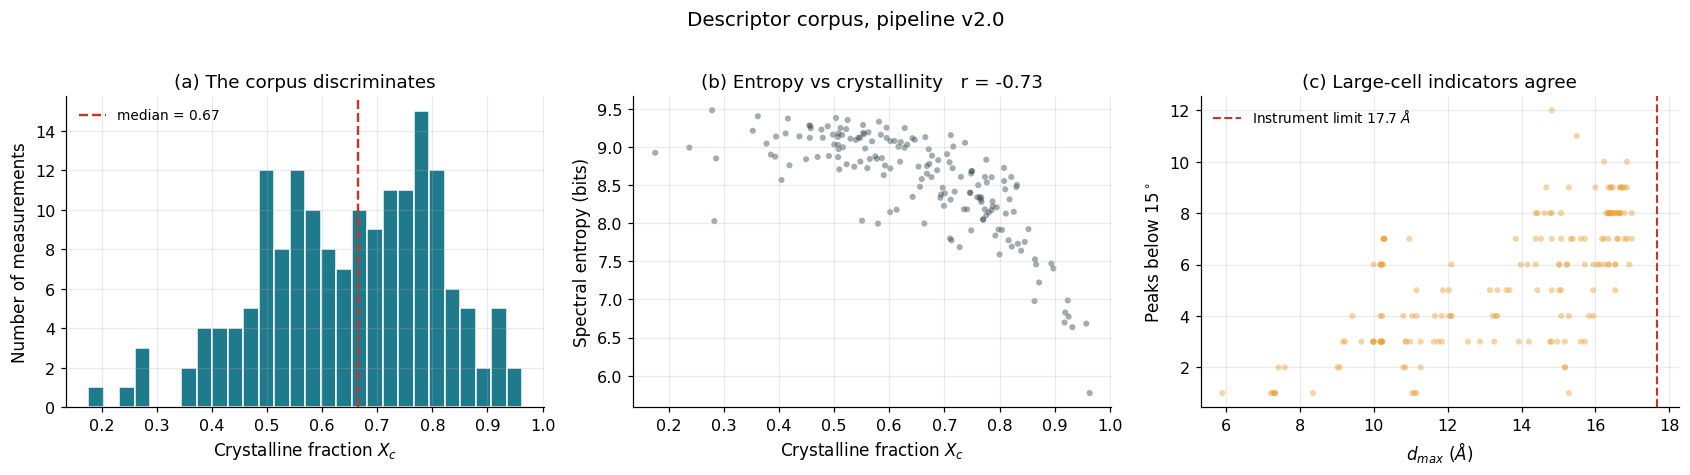

Correlacion entropia - cristalinidad: r = -0.734
Negativa: una muestra cristalina concentra su intensidad en pocas reflexiones
(entropia baja); una amorfa la reparte por una joroba ancha (entropia alta).


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.2))

ax = axes[0]
ax.hist(corpus['crystalline_fraction'].dropna(), bins=28, color=C_CRIST, edgecolor='white')
ax.axvline(corpus['crystalline_fraction'].median(), color=C_PICO, ls='--', lw=1.6,
           label=f"median = {corpus['crystalline_fraction'].median():.2f}")
ax.set_xlabel('Crystalline fraction $X_c$'); ax.set_ylabel('Number of measurements')
ax.set_title('(a) The corpus discriminates')
ax.legend(fontsize=9)

ax = axes[1]
ax.scatter(corpus['crystalline_fraction'], corpus['spectral_entropy'],
           s=16, alpha=0.45, color=C_CRUDO, edgecolor='none')
r = corpus['crystalline_fraction'].corr(corpus['spectral_entropy'])
ax.set_xlabel('Crystalline fraction $X_c$'); ax.set_ylabel('Spectral entropy (bits)')
ax.set_title(f'(b) Entropy vs crystallinity   r = {r:+.2f}')

ax = axes[2]
ax.scatter(corpus['d_max_angstrom'], corpus['n_peaks_below_15deg'],
           s=16, alpha=0.45, color=C_AMORFO, edgecolor='none')
ax.axvline(D_MAX_OBSERVABLE_A, color=C_PICO, ls='--', lw=1.4,
           label=f'Instrument limit {D_MAX_OBSERVABLE_A:.1f} $\\AA$')
ax.set_xlabel(r'$d_{max}$ ($\AA$)'); ax.set_ylabel(f'Peaks below {LOW_ANGLE_WINDOW_DEG:.0f}$^\\circ$')
ax.set_title('(c) Large-cell indicators agree')
ax.legend(fontsize=9)

fig.suptitle(f'Descriptor corpus, pipeline {PIPELINE_VERSION}', fontsize=13, y=1.02)
fig.tight_layout(); plt.show()

print(f'Correlacion entropia - cristalinidad: r = {r:+.3f}')
print('Negativa: una muestra cristalina concentra su intensidad en pocas reflexiones')
print('(entropia baja); una amorfa la reparte por una joroba ancha (entropia alta).')

**Qué se ve.** En (a), la cristalinidad se reparte por un rango amplio en vez de
apelotonarse en un extremo: el descriptor **discrimina**, que es lo único que le
pedimos. En (b), la relación con la entropía es clara y negativa. En (c), los dos
indicadores independientes de celda grande —el espaciado máximo y el número de
reflexiones a bajo ángulo— se mueven juntos, que es la validación cruzada barata de que
ninguno de los dos está midiendo un artefacto.

> **La estadística implicada en (b).** `r` es el coeficiente de correlación de Pearson,
> que mide relación **lineal** entre dos variables y va de −1 a +1. Que salga −0,70 no
> significa que la entropía "cause" la cristalinidad: son dos formas de mirar la misma
> propiedad física. Precisamente por eso hay que tener cuidado al meter las dos en un
> modelo: son parcialmente **colineales**, y dos variables colineales se reparten la
> importancia entre sí, con lo que ninguna de las dos parece importante aunque juntas
> lo sean.

In [31]:
# La pregunta del principio, ahora contestable en SQL
consulta_util = sql("""
    SELECT d.sample_code, s.metal_center, s.linker,
           ROUND(d.crystalline_fraction::numeric, 3) AS Xc,
           ROUND(d.d_max_angstrom::numeric, 2)       AS d_max_A,
           d.n_peaks_below_15deg                     AS picos_bajo_angulo,
           ROUND(d.signal_snr_area::numeric, 1)      AS SNR
    FROM pxrd_descriptors d
    JOIN synthesis_experiments s USING (sample_code)
    WHERE d.pipeline_version   = %(v)s
      AND d.crystallinity_reliable
      AND d.d_max_angstrom     > 12          -- celda grande
      AND d.crystalline_fraction < 0.6       -- cristaliza mal
    ORDER BY d.d_max_angstrom DESC
    LIMIT 12;
""", params={'v': PIPELINE_VERSION})

print('"Sintesis con celda grande que cristalizan mal" -- candidatas a repetir:')
display(consulta_util)

"Sintesis con celda grande que cristalizan mal" -- candidatas a repetir:


,sample_code,metal_center,linker,xc,d_max_a,picos_bajo_angulo,snr
0,RS97,Bi,H6ttbmp,0.503,16.98,7,2.3
1,RS1462,Mg,H6ttbmp,0.393,16.92,6,4.2
2,RS1374,Ca,H6ttbmp,0.470,16.85,10,1.5
3,RS603,Mg,H6ttbmp,0.437,16.85,9,7.7
4,RS1811,Mg,H6ttbmp,0.395,16.79,9,3.4
5,RS622,Bi,H6ttbmp,0.553,16.79,8,2.5
6,RS1275,Ca,Et6ttbmp,0.362,16.79,7,2.6
7,RS1805,Mg,H6ttbmp,0.498,16.66,9,2.4
8,RS1803,Mg,H6ttbmp,0.552,16.66,9,3.5
9,RS721,Bi,H6ttbmp,0.585,16.60,7,3.2


# 14. Buenas prácticas que salen de este cuaderno

Ninguna es específica de difracción; todas cuestan poco y evitan errores caros.

1. **Un cuaderno sin ejecutar no es un resultado, es una propuesta.** Si todas las
   celdas tienen `execution_count: None`, los errores de cálculo sobreviven porque nadie
   los ha visto fallar.

2. **Calibra contra algo cuya respuesta ya conoces.** Un parámetro "calibrado" que nadie
   ha calibrado es una opinión. Media hora de barrido contra un blanco, una muestra
   amorfa y una cristalina convierte una decisión arbitraria en una decisión defendible
   — y puede cambiar el valor elegido.

3. **Calcula los descriptores del blanco.** Es la prueba más barata que existe y la que
   más errores caza: si el pipeline dice algo interesante sobre un portamuestras vacío,
   el pipeline está roto. Nadie lo hace porque el blanco "no es una muestra".

4. **Un algoritmo fuera de su propósito falla en silencio.** arPLS busca suelos; pedirle
   una envolvente devuelve ceros plausibles, no una excepción. Cuando un método nuevo
   produce números que quedan bien, desconfía.

5. **Verifica los rangos físicos de cada magnitud.** Un ángulo 2θ mayor que 180°, una
   fracción mayor que 1, un tamaño negativo. Una línea de código, y caza en el día 1
   errores que si no viven meses.

6. **Sospecha de cualquier fórmula que mezcle un sumatorio con una integral.** Si una
   lleva dentro el paso de la rejilla y la otra no, el resultado sale escalado por
   1/paso. Aquí habría sido ×50.

7. **Simplifica cada fórmula a mano antes de darla por buena.** Un descriptor que se
   reduce algebraicamente a otro no es un descriptor, es una columna duplicada con un
   nombre que engaña.

8. **El orden de las operaciones importa tanto como las operaciones.** Normalizar
   después de ajustar la línea base da resultados distintos que normalizar antes, y solo
   uno de los dos órdenes hace comparables las medidas entre sí.

9. **Distingue "no hay señal" de "no se ha mirado".** Rellenar con ceros el rango no
   medido es afirmar algo que no se ha comprobado. Una máscara de validez cuesta lo
   mismo y no miente.

10. **Guarda con qué reglas se calculó cada fila.** `pipeline_version`,
    `baseline_lambda`, `peak_sigma_k`. Sin ellas, dos generaciones de números conviven
    en la misma tabla sin forma de distinguirlas.

11. **Si un descriptor puede no ser una medida, dilo en una columna.** `d_max_saturated`
    y `crystallinity_reliable` no cambian ningún número: cambian lo que se puede
    afirmar con él.

# Cierre

Lo que hay ahora en la base de datos, y lo que no.

**Hay:** una tabla `pxrd_descriptors` con un vector de descriptores por medida, cada una documentada
en `data_dictionary`, calculadas por un único módulo (`src/pxrd_descriptors.py`) cuyos
parámetros están calibrados contra referencias reales del laboratorio y cuya versión
queda escrita en cada fila.

**No hay, y conviene tenerlo claro:**

- **La cristalinidad no es una etiqueta.** Es un número reproducible que ordena el
  corpus. Que una muestra tenga la fase deseada es un juicio distinto, y ese juicio va
  en `pxrd_labels`.
- **`d_max_angstrom` está limitado por el equipo a 17,66 Å.** No es una propiedad del
  material.
- **Scherrer da un índice comparativo**, no un tamaño de cristalito absoluto.

## Sobre el NMF: los patrones que hacen falta no son el blanco y el patrón

Hay una pregunta razonable que conviene contestar bien porque la respuesta es
contraintuitiva. La **factorización en matrices no negativas** (NMF) descompone el
corpus completo en unos pocos *patrones componentes* que, combinados con pesos no
negativos, reconstruyen cada difractograma. Su entrada **no son las referencias**: es la
**matriz entera de N medidas × 2.250 puntos**. El NMF aprende las componentes *de los
propios datos*, y necesita muchas muestras que compartan fases para poder separarlas.

El blanco y el patrón hacen otro trabajo, igual de necesario pero distinto:

| | Para qué sirve | Se usa en |
|---|---|---|
| **Blanco** | Definir el "cero": qué mide el equipo sin muestra | Calibrar λ, validar que el pipeline no inventa señal |
| **Patrón** | Definir la resolución instrumental (anchura mínima) | Poner suelo a `fwhm_min_deg` y a Scherrer |
| **Precursores** | Reconocer señal de material de partida sin reaccionar | Descartar falsos positivos de fase nueva |
| **Simulados de SCXRD** | Comparar con estructuras propias ya resueltas | Triaje de **novedad** |
| **Corpus completo** | **La entrada del NMF** | Descomposición en fases |

Para el NMF, entonces, hace falta el lote completo de descriptores y curvas
resampleadas, no las referencias. Y una advertencia: aplicado a las curvas crudas el
NMF gasta su primera componente en describir el fondo. Hay que alimentarlo con la
**señal neta** que produce la sección 5.

## Qué sigue

1. **Lanzar el lote completo** sobre las ~1.880 medidas, fuera del cuaderno.
2. **Etiquetar** (`pxrd_labels`). Es el cuello de botella real: los descriptores no
   necesitan etiquetas, pero cualquier modelo sí.
3. **NMF** sobre la matriz completa de señal neta.
4. **Triaje de novedad** comparando posiciones de pico contra los patrones simulados de
   las estructuras propias resueltas por monocristal. Según el roadmap, ese es el
   producto real del proyecto, más que la cristalinidad.